## Aco Hyperparameter Grid Search

Debido a que se noto un compartamiento extraño en como se comportaba el solver [aco](../solvers/aco.py) en simulaciones de distintos tamaños, se decidio hacer un analisis de como cambian los resultados para tres tipos de instancias (small, medium, big) segun variamos los parametros. Por el momento solo nos concentramos en los parametros: `num_ants`, `num_iters` que luego de algunas observaciones resultaron ser los mas influyentes


### Importante

Mientras que se realizaba el analisis de los mismos graficos que vienen a continuacion, pudimos encontrar un problema en la clase [synthetic](../data/generators/synthetic.py) que generaba instancias infeasibles para problemas de tamaño grande. El problema se basaba en como generaba las ventanas de tiempo de cada cliente.
En la version anterior del codigo, si bien se parametrizaba la longitud de la ventana con las variables, se utilizaba un random para generar las ventas de cada cliente en el rango debido segun la configuracion de [synthetic.yaml](../conf/generator/synthetic.yaml) pero no se tenia en cuanta la feasibilidad de esas instancias generadas. En cambio ahora lo que se hace es asignar customers a depots, verificando que se cumpla las restriciones de cargas, simular un recorrido y a partir de ahi armar las ventanas de tiempo para que la solucion sea feasible. De esta forma podemos asegurar la generacion de instancias feasibles a diferencia de antes que generabamos intancias y no sabiamos si el solver las marcaba infeasibles porque el mismo solver no encontraba la solucion o porque no existia solucion en si.

Se puede recrear el comportamiento corriendo los experimentos adjuntos mas abajo y restaurando la version del repo a la siguiente: `f6f3b71468f66270861a9fe196972cbbfd0d4eec`. El analisi siguiente se realizo luego de solucionar dicho error.


### Objetivos

Para que quede bien claro los objetivos de esta notebook:
1. Entender la relacion de las varaibles `num_ants` y `num_iters` con el tamaño del problema
2. Encontrar los valores optimos para cada tamaño de problema
3. Deducir una regla, funcion para los parametros

In [1]:
import sqlite3
import pandas as pd
from pathlib import Path
import re 
import numpy as np 

DB_PATH = Path("../../results/results.db")
sizes = ["small", "medium", "big", "large"]

def load_results_table(db_path: Path, table_name: str = "run_results") -> pd.DataFrame:
    with sqlite3.connect(db_path) as conn:
        df = pd.read_sql_query(f"SELECT * FROM {table_name}", conn)
    return df

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_ants(exp_id):
        m = re.search(r"ants(\d+)", exp_id)
        return int(m.group(1)) if m else np.nan

    def extract_it(exp_id):
        m = re.search(r"it(\d+)", exp_id)
        return int(m.group(1)) if m else np.nan

    def extract_C(text):
        match = re.search(r'C(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_V(text):
        match = re.search(r'V(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_rho(text):
        match = re.search(r'rho([0-9.]+)', text)
        return float(match.group(1)) if match else None

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    
    df["ants"] = df["experiment_id"].apply(extract_ants)
    df["it"] = df["experiment_id"].apply(extract_it)
    df["c"] = df["experiment_id"].apply(extract_C)
    df["v"] = df["experiment_id"].apply(extract_V)
    df["rho"] = df["experiment_id"].apply(extract_rho)
    df['dim'] = df['c'] + 2 * df['v']
    df["size"] = df["c"].apply(extract_size)
    return df


In [2]:
df = filter_by_experiment_prefix(df=load_results_table(DB_PATH), prefix="aco_hyperparameter_C")

df = prepare_dataframe(df)
print("Total rows:", len(df))
print(df.info())
print(df.head())

Total rows: 74160
<class 'pandas.core.frame.DataFrame'>
Index: 74160 entries, 0 to 74387
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   74160 non-null  int64  
 1   experiment_id        74160 non-null  object 
 2   instance_id          74160 non-null  object 
 3   instance_repetition  74160 non-null  int64  
 4   solver               74160 non-null  object 
 5   status               74160 non-null  object 
 6   feasible             74160 non-null  int64  
 7   cost                 74160 non-null  float64
 8   runtime              74160 non-null  float64
 9   routes               74160 non-null  object 
 10  not_visited          74160 non-null  object 
 11  created_at           74160 non-null  object 
 12  ants                 74160 non-null  int64  
 13  it                   74160 non-null  int64  
 14  c                    74160 non-null  float64
 15  v                    74

Tengamos en mente el esquema de la siguinte figura: 

![Experimento](../src/experiment_architecture.png).

y tambien el comando que usamos para generar los experimentos: 

```bash
python main.py -m \
  solvers.aco.num_ants=10,100,1000,10000 \
  solvers.aco.num_iter=10,100,1000,10000 \
  experiments.num_customers=10 \
  experiments.num_vehicles=3
  'experiments.name=aco_hyperparameter_search_small_ants${solvers.aco.num_ants}_it${solvers.aco.num_iter}'
```

Entonces, vamos a crear un experimento por cada tamaño de problema, y a su vez por cada tamaño de problema creamos un experimento que fija valores para **num_ants** y **num_iter**.
El objetivo es ver como se comportan los distintos experimentos de un mismo tamaño, segun cambian los parametros de aco.
Por ultimo recordemos que cada instancia se corre **instance_reps** veces que en este caso esta fijado en 10, como tambien para cada experimento puntual generemos 10 muestras del mismo tipo.

pd: todos los comandos utilizados para generar los experimentos analizados en esta notebook
```bash
python main.py -m \
  solvers.aco.num_ants=10,100,1000,10000 \
  solvers.aco.num_iter=10,100,1000,10000 \
  experiments.num_customers=10 \
  experiments.num_vehicles=3
  'experiments.name=aco_hyperparameter_search_small_ants${solvers.aco.num_ants}_it${solvers.aco.num_iter}'

python main.py -m \
  solvers.aco.num_ants=10,100,1000,10000 \
  solvers.aco.num_iter=10,100,1000,10000 \
  experiments.num_customers=20 \
  experiments.num_vehicles=10 \
  'experiments.name=aco_hyperparameter_search_medium_ants${solvers.aco.num_ants}_it${solvers.aco.num_iter}'


python main.py -m \
  solvers.aco.num_ants=1,5,10,50,100 \
  solvers.aco.num_iter=10,100,1000,10000 \
  experiments.num_customers=30 \
  experiments.num_vehicles=15 \
  'experiments.name=aco_hyperparameter_search_intermediate_ants${solvers.aco.num_ants}_it${solvers.aco.num_iter}'


python main.py -m \
  solvers.aco.num_ants=5,10,20,40,100 \
  solvers.aco.num_iter=100000 \
  experiments.num_customers=30 \
  experiments.num_vehicles=20 \
  'experiments.name=aco_hyperparameter_search_intermediate4_ants${solvers.aco.num_ants}_it${solvers.aco.num_iter}'


python main.py -m \
  solvers.aco.num_ants=10,100,1000,10000 \
  solvers.aco.num_iter=10,100,1000,10000 \
  experiments.num_customers=50 \
  experiments.num_vehicles=20 \
  'experiments.name=aco_hyperparameter_search_big_ants${solvers.aco.num_ants}_it${solvers.aco.num_iter}'

python main.py -m \
  solvers.aco.num_ants=2500 \
  solvers.aco.num_iter=10000 \
  experiments.num_customers=50 \
  experiments.num_vehicles=20 \
  'experiments.name=aco_hyperparameter_search_large3_ants${solvers.aco.num_ants}_it${solvers.aco.num_iter}'
```

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns

SIZE_COLORS = {
    "small": "tab:blue",
    "medium": "tab:orange",
    "big": "tab:red",
    "large": "yellow",
}


# Extract ants and iterations
def extract_label(exp_id):
    ants_match = re.search(r"ants(\d+)", exp_id)
    it_match = re.search(r"it(\d+)", exp_id)
    ants = ants_match.group(1) if ants_match else "?"
    it = it_match.group(1) if it_match else "?"
    return f"ants_{ants} it_{it}"


<Axes: >

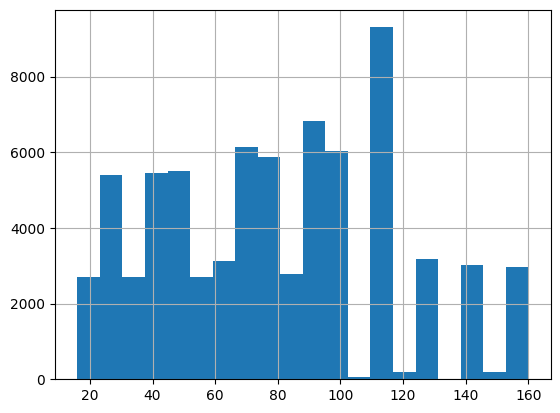

In [4]:
df['dim'].hist(bins=20)

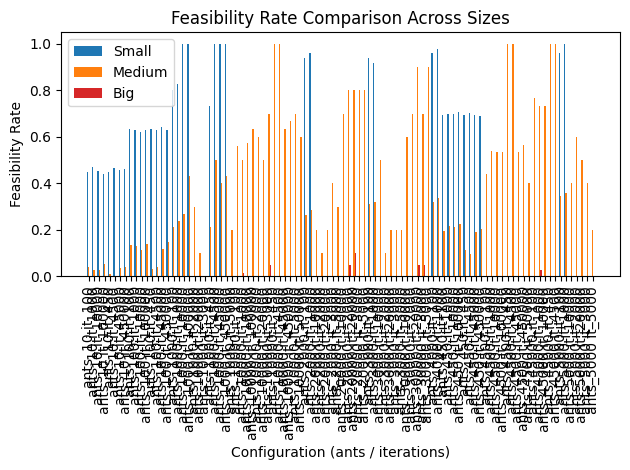

In [5]:
def plot_feasibility_all_sizes(df: pd.DataFrame):
    results = []

    for size in sizes:
        df_size = df[df["size"] == size].copy()

        if df_size.empty:
            continue

        summary = (
            df_size
            .groupby("experiment_id")["feasible"]
            .agg(["sum", "count"])
            .reset_index()
        )

        summary["feasibility_rate"] = summary["sum"] / summary["count"]
        summary["label"] = summary["experiment_id"].apply(extract_label)
        summary["size"] = size

        results.append(summary[["label", "feasibility_rate", "size"]])

    final_df = pd.concat(results)
    pivot_df = final_df.pivot_table(
        index="label",
        columns="size",
        values="feasibility_rate"
    ).fillna(0)

    pivot_df = pivot_df.sort_index()

    x = np.arange(len(pivot_df.index))
    width = 0.25

    plt.figure()
    for i, size in enumerate(sizes):
        if size in pivot_df.columns:
            plt.bar(
                x + i * width,
                pivot_df[size],
                width,
                label=size.capitalize(),
                color=SIZE_COLORS[size]
            )
    plt.xticks(x + width, pivot_df.index, rotation=90)
    plt.ylabel("Feasibility Rate")
    plt.xlabel("Configuration (ants / iterations)")
    plt.title("Feasibility Rate Comparison Across Sizes")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_feasibility_all_sizes(prepare_dataframe(df))

/tmp/ipykernel_7099/2532317983.py:23: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = plt.imshow(
/tmp/ipykernel_7099/2532317983.py:23: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = plt.imshow(


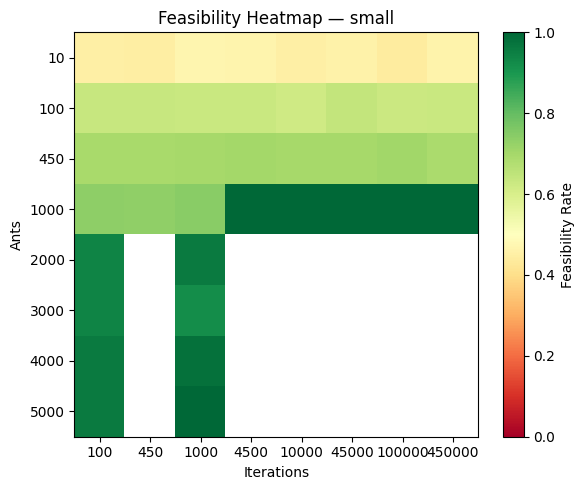

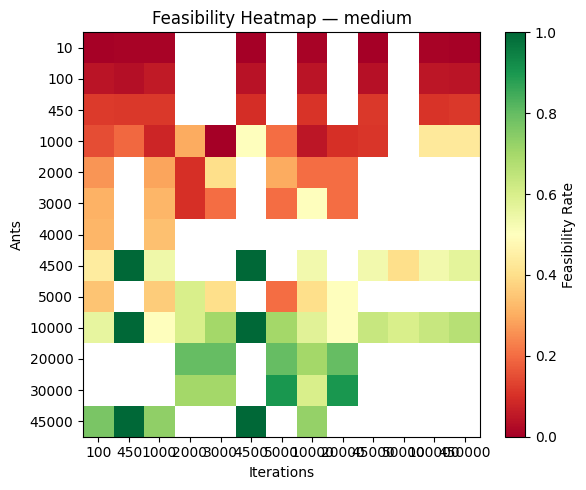

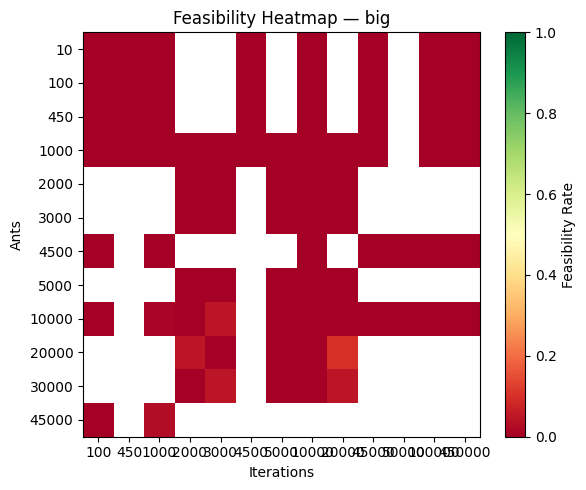

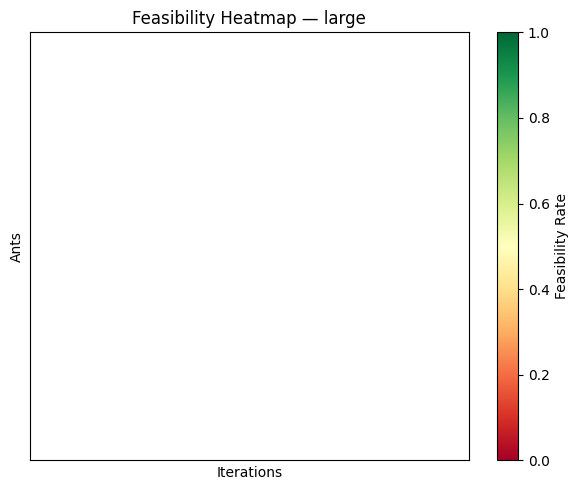

In [6]:
def heatmap_feasibility(df):

    for size in sizes:

        df_size = df[df["size"] == size]
        summary = (
            df_size
            .groupby(["ants", "it"])["feasible"]
            .mean()
            .reset_index()
        )

        pivot = summary.pivot(
            index="ants",
            columns="it",
            values="feasible"
        )

        pivot = pivot.sort_index().sort_index(axis=1)

        plt.figure(figsize=(6, 5))

        im = plt.imshow(
            pivot,
            aspect="auto",
            cmap="RdYlGn",
            vmin=0,
            vmax=1
        )

        plt.colorbar(im, label="Feasibility Rate")

        plt.xticks(range(len(pivot.columns)), pivot.columns)
        plt.yticks(range(len(pivot.index)), pivot.index)

        plt.xlabel("Iterations")
        plt.ylabel("Ants")
        plt.title(f"Feasibility Heatmap — {size}")
        plt.tight_layout()
    plt.show()
heatmap_feasibility(df)

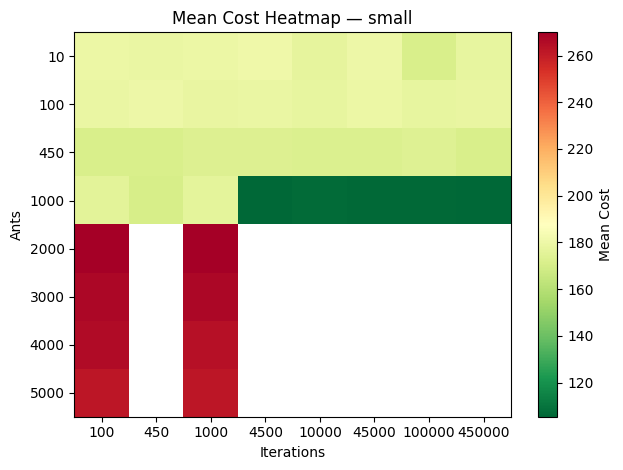

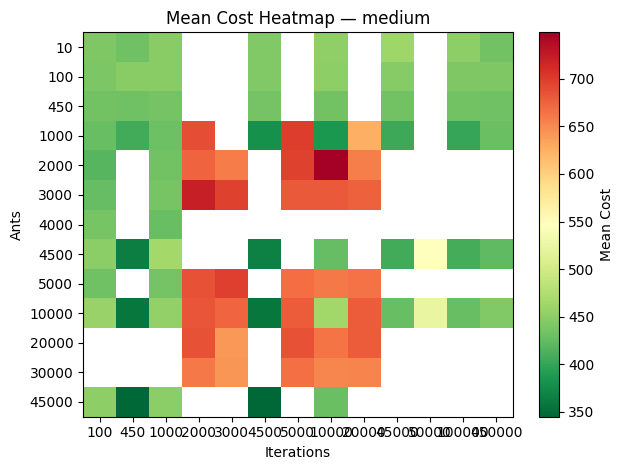

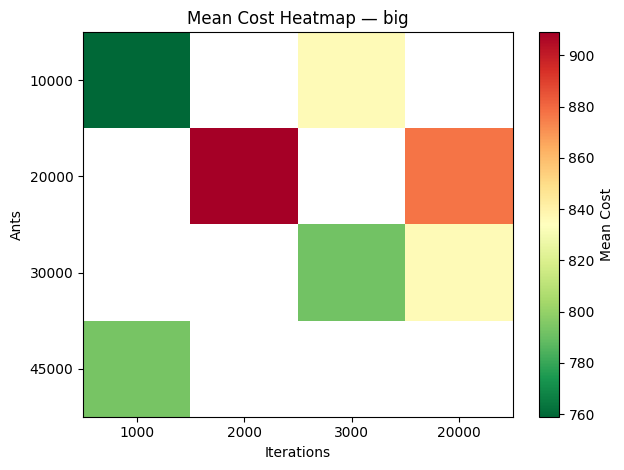

/tmp/ipykernel_7099/3379877099.py:13: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.imshow(pivot, aspect="auto")
/tmp/ipykernel_7099/3379877099.py:13: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.imshow(pivot, aspect="auto")
/tmp/ipykernel_7099/3379877099.py:15: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = plt.imshow(
/tmp/ipykernel_7099/3379877099.py:15: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = plt.imshow(


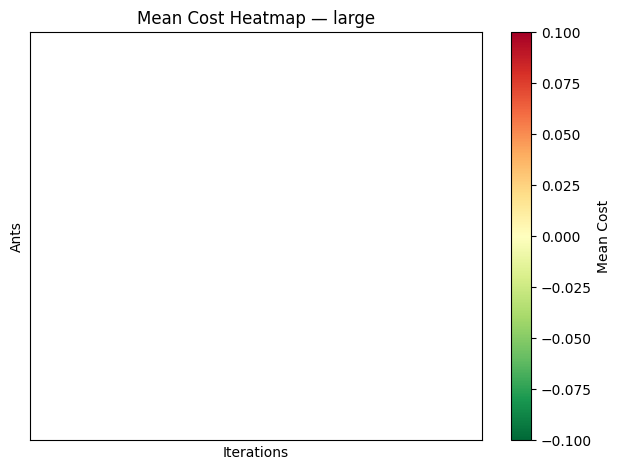

In [7]:
def heatmap_cost(df):
    for size in sizes:
        df_size = df[(df["size"] == size) & (df["feasible"] == True)]
        pivot = (
            df_size
            .groupby(["ants", "it"])["cost"]
            .mean()
            .reset_index()
            .pivot(index="ants", columns="it", values="cost")
        )

        plt.figure()
        plt.imshow(pivot, aspect="auto")

        im = plt.imshow(
            pivot,
            aspect="auto",
            cmap="RdYlGn_r",
            vmin=pivot.min().min(),
            vmax=pivot.max().max()
        )

        plt.colorbar(im, label="Mean Cost")
        
        plt.xticks(range(len(pivot.columns)), pivot.columns)
        plt.yticks(range(len(pivot.index)), pivot.index)
        plt.xlabel("Iterations")
        plt.ylabel("Ants")
        plt.title(f"Mean Cost Heatmap — {size}")
        plt.tight_layout()
        plt.show()

heatmap_cost(df)

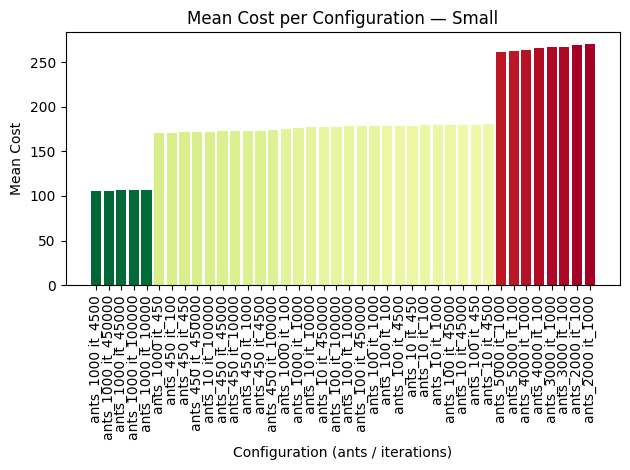

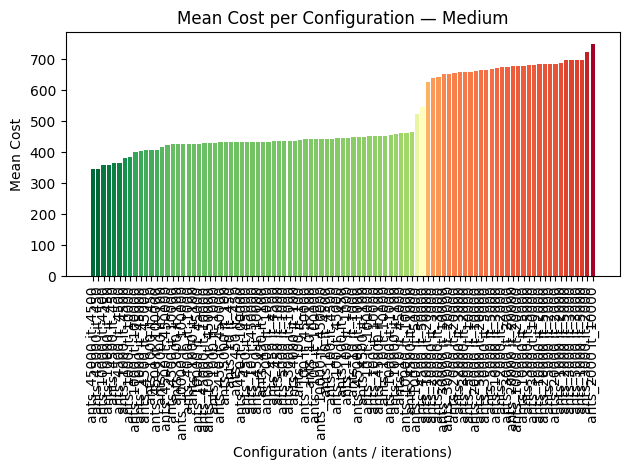

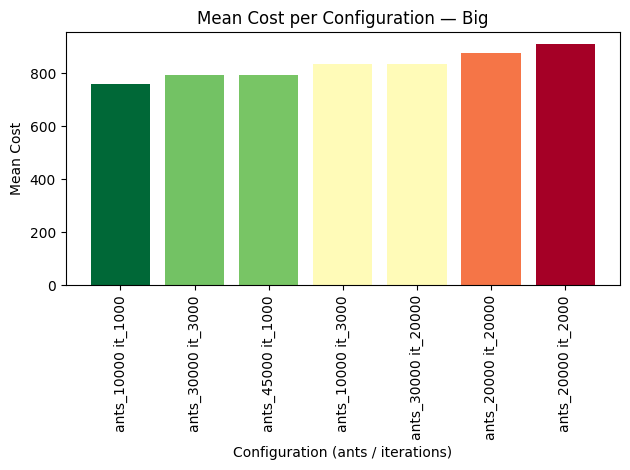

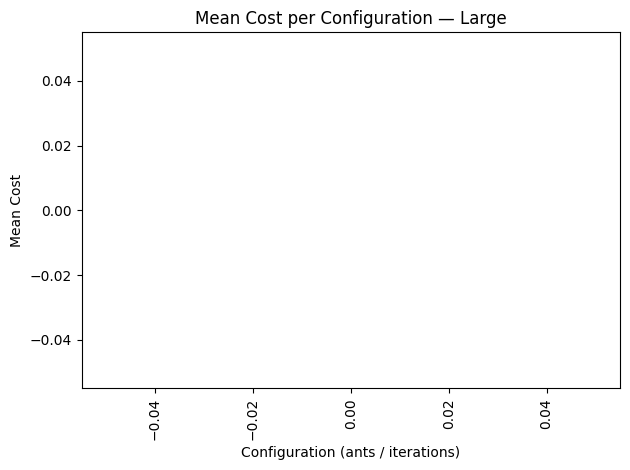

In [8]:
def plot_mean_cost_by_config(df: pd.DataFrame):
    for size in sizes:
        size = size.lower()
        df_filtered = df[
            (df["size"] == size) &
            (df["feasible"] == True)
        ].copy()

        df_filtered["label"] = df_filtered["experiment_id"].apply(extract_label)

        summary = (
            df_filtered
            .groupby("label")["cost"]
            .mean()
            .reset_index()
            .sort_values("cost")
        )

        norm = plt.Normalize(summary["cost"].min(), summary["cost"].max())
        colors = plt.cm.RdYlGn_r(norm(summary["cost"]))

        plt.figure()
        plt.bar(summary["label"], summary["cost"], color=colors)

        plt.xticks(rotation=90)
        plt.ylabel("Mean Cost")
        plt.xlabel("Configuration (ants / iterations)")
        plt.title(f"Mean Cost per Configuration — {size.capitalize()}")
        plt.tight_layout()
        plt.show()

plot_mean_cost_by_config(df)

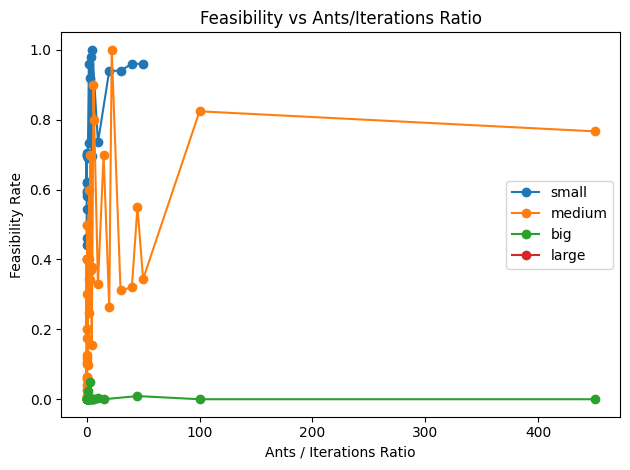

In [9]:
def plot_feasibility_vs_ratio(df):

    df = df.copy()
    df["ratio"] = df["ants"] / df["it"]

    summary = (
        df.groupby(["size", "ratio"])["feasible"]
        .mean()
        .reset_index()
    )

    plt.figure()

    for size in sizes:
        subset = summary[summary["size"] == size]
        plt.plot(subset["ratio"], subset["feasible"], marker="o", label=size)

    plt.xlabel("Ants / Iterations Ratio")
    plt.ylabel("Feasibility Rate")
    plt.title("Feasibility vs Ants/Iterations Ratio")
    plt.legend()
    plt.tight_layout()
    plt.show()
plot_feasibility_vs_ratio(df)

In [10]:
def plot_3d_surface_cost_interactive(df: pd.DataFrame):
    for size in sizes:
        df_size = df[(df["size"] == size) & (df["feasible"] == True)]

        summary = (
            df_size
            .groupby(["ants", "it"])["cost"]
            .mean()
            .reset_index()
        )

        pivot = summary.pivot(index="ants", columns="it", values="cost")

        X = pivot.columns.values
        Y = pivot.index.values
        Z = pivot.values

        fig = go.Figure(data=[
            go.Surface(
                z=Z,
                x=X,
                y=Y,
                colorscale="Viridis",
                colorbar=dict(title="Mean Cost")
            )
        ])

        fig.update_layout(
            title=f"Interactive 3D Cost Surface — {size}",
            scene=dict(
                xaxis_title="Iterations",
                yaxis_title="Ants",
                zaxis_title="Mean Cost"
            ),
            autosize=True
        )
        fig.show()
plot_3d_surface_cost_interactive(df)

small
medium
big
large


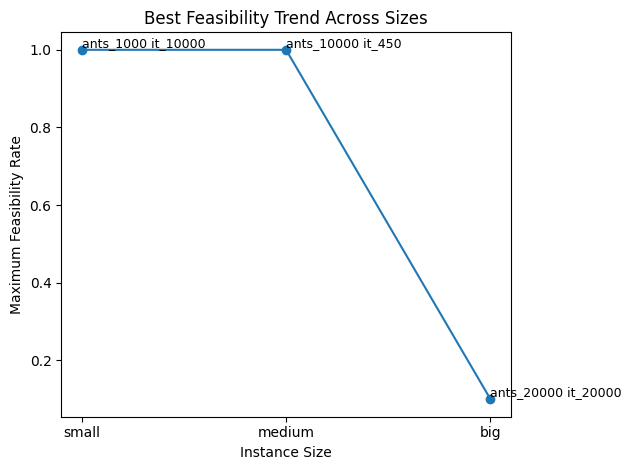

In [11]:
def plot_best_feasibility_trend(df: pd.DataFrame):

    best_results = []

    for size in sizes:
        print(size)
        df_size = df[df["size"] == size].copy()

        if df_size.empty:
            continue

        df_size["label"] = df_size["experiment_id"].apply(extract_label)

        summary = (
            df_size
            .groupby("label")["feasible"]
            .mean()
            .reset_index()
        )

        best_row = summary.loc[summary["feasible"].idxmax()]

        best_results.append({
            "size": size,
            "feasibility": best_row["feasible"],
            "label": best_row["label"]
        })

    best_df = pd.DataFrame(best_results)

    # Ordenar correctamente
    best_df["size"] = pd.Categorical(best_df["size"], categories=sizes, ordered=True)
    best_df = best_df.sort_values("size")

    plt.figure()
    plt.plot(best_df["size"], best_df["feasibility"], marker="o")

    for _, row in best_df.iterrows():
        plt.text(row["size"], row["feasibility"], row["label"],
                 fontsize=9, ha='left', va='bottom')

    plt.ylabel("Maximum Feasibility Rate")
    plt.xlabel("Instance Size")
    plt.title("Best Feasibility Trend Across Sizes")
    plt.tight_layout()
    plt.show()
plot_best_feasibility_trend(df)

## Factos

A medida que crece el problema:
- Bajan las ants
- Suben las iteraciones
- Baja rho (menos agresivo)

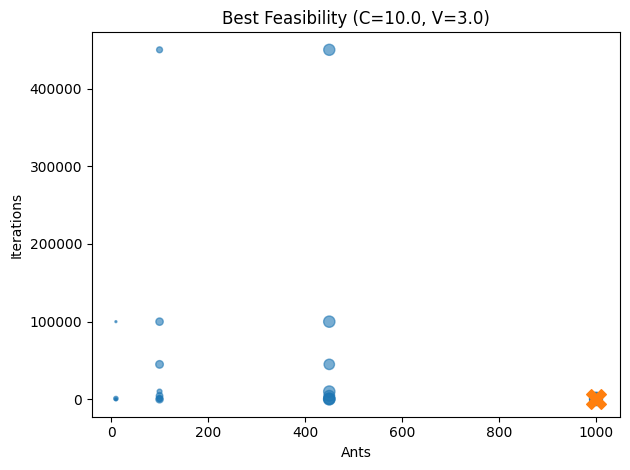

C=10.0, V=3.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 0.43
----------------------------------------


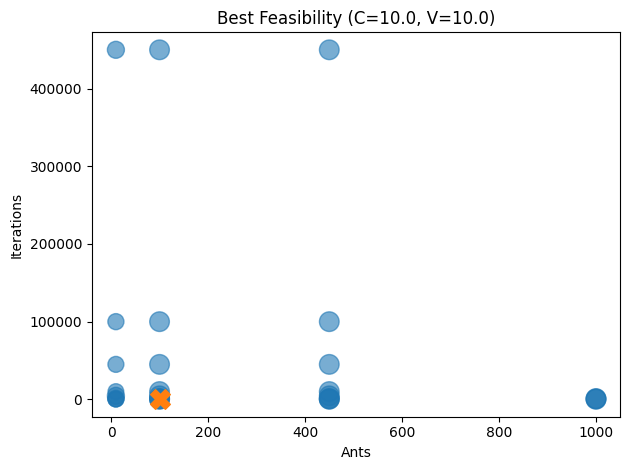

C=10.0, V=10.0
Best ants: 100.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


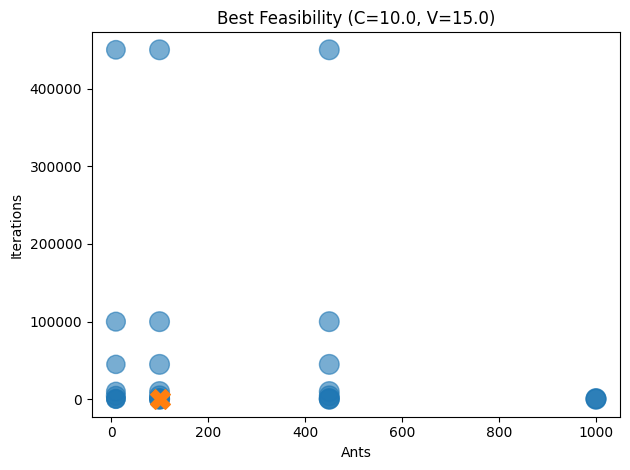

C=10.0, V=15.0
Best ants: 100.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


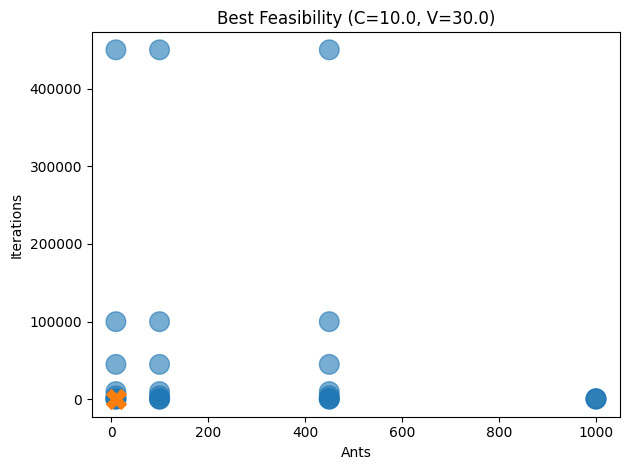

C=10.0, V=30.0
Best ants: 10.0
Best it: 450.0
Feasibility: 1.0
----------------------------------------


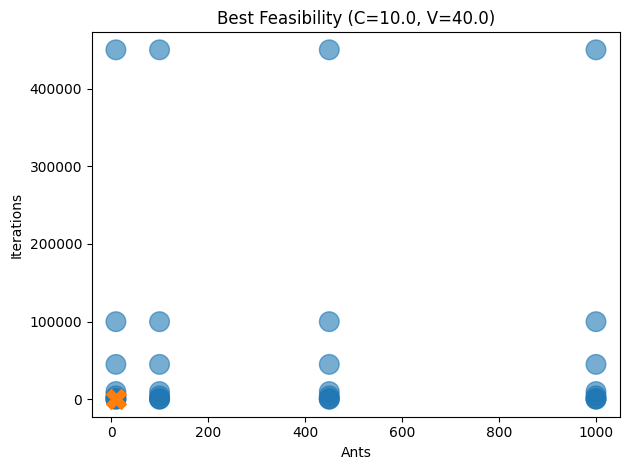

C=10.0, V=40.0
Best ants: 10.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


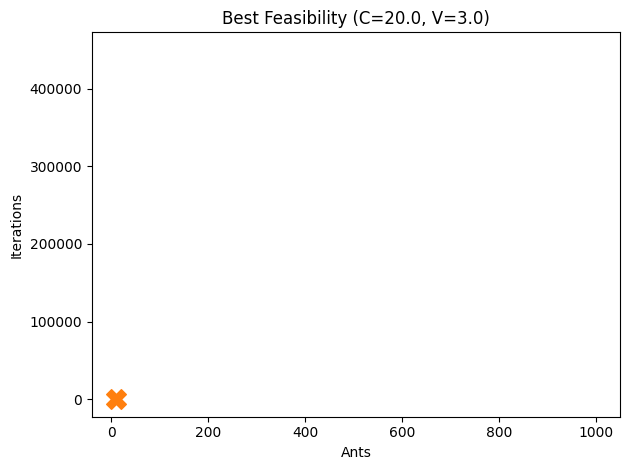

C=20.0, V=3.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


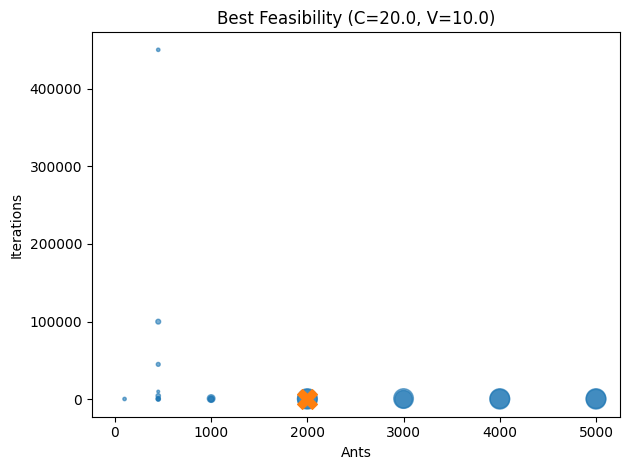

C=20.0, V=10.0
Best ants: 2000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


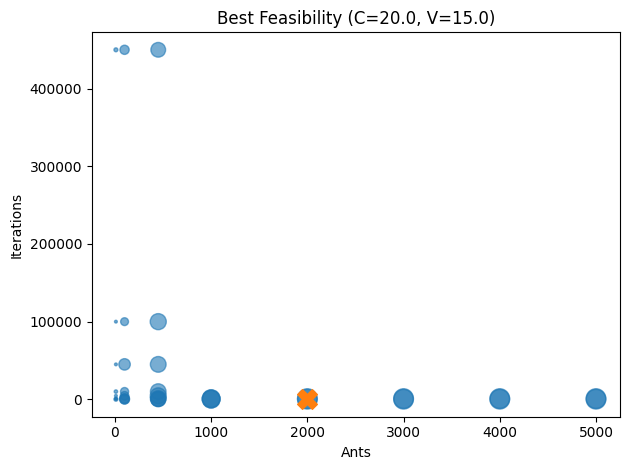

C=20.0, V=15.0
Best ants: 2000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


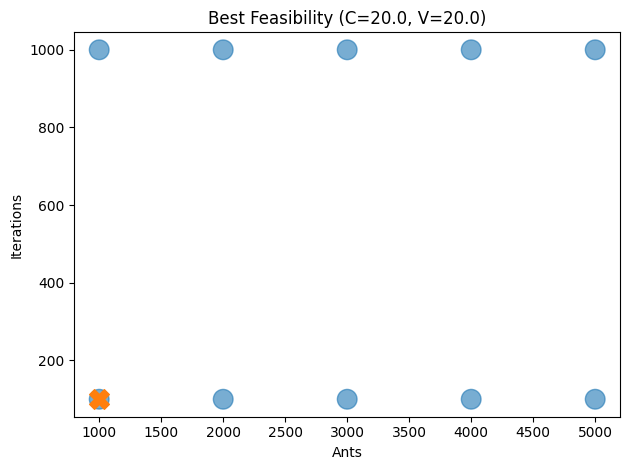

C=20.0, V=20.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


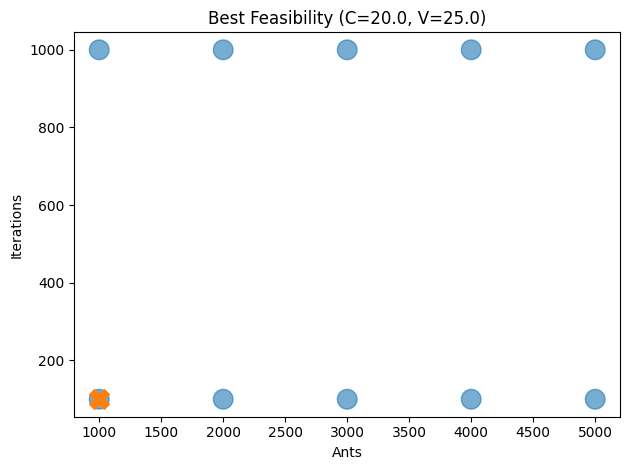

C=20.0, V=25.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


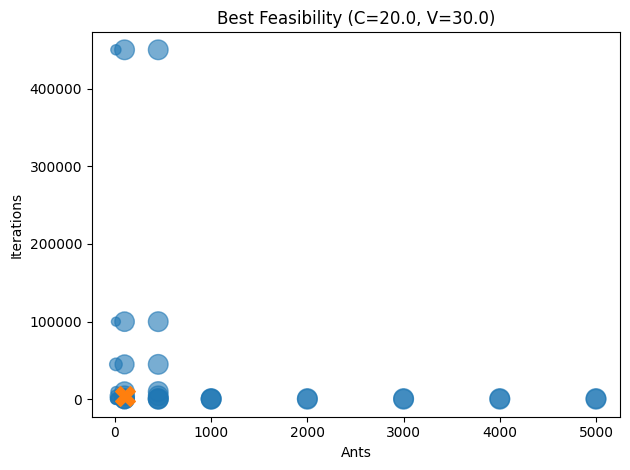

C=20.0, V=30.0
Best ants: 100.0
Best it: 4500.0
Feasibility: 1.0
----------------------------------------


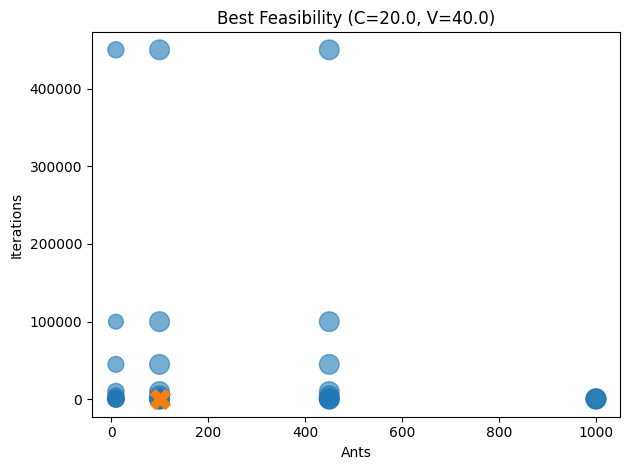

C=20.0, V=40.0
Best ants: 100.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


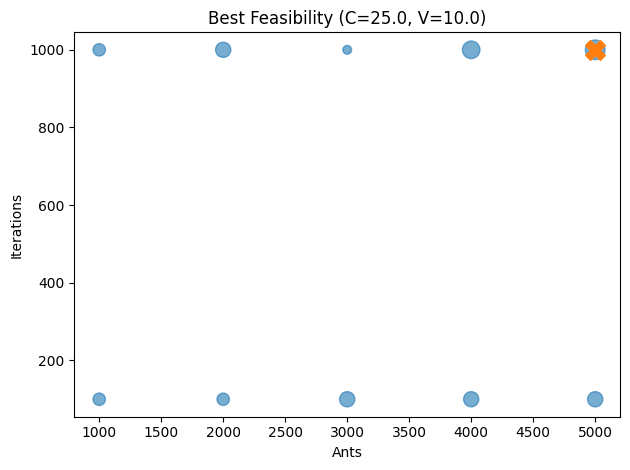

C=25.0, V=10.0
Best ants: 5000.0
Best it: 1000.0
Feasibility: 1.0
----------------------------------------


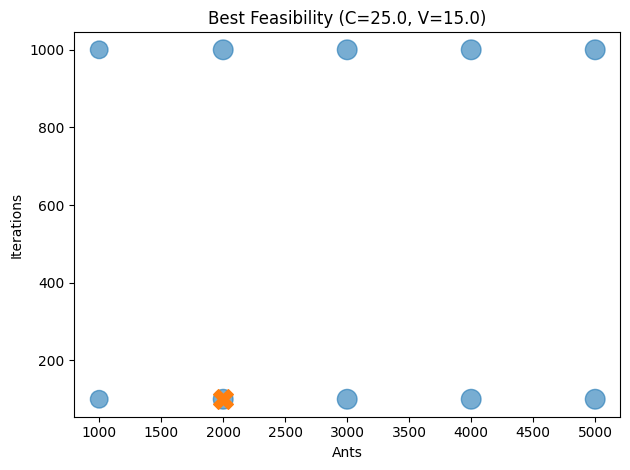

C=25.0, V=15.0
Best ants: 2000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


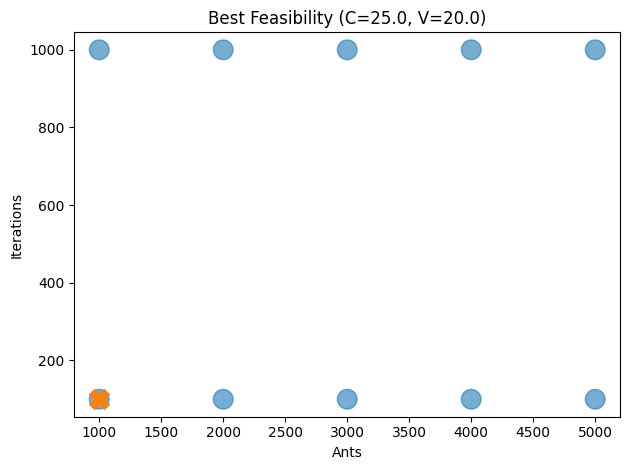

C=25.0, V=20.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


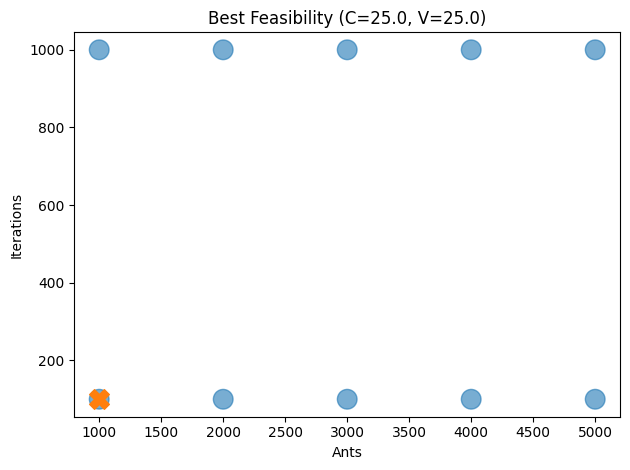

C=25.0, V=25.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


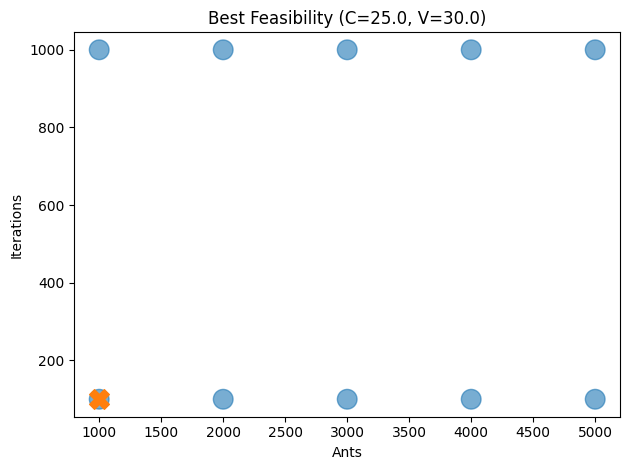

C=25.0, V=30.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


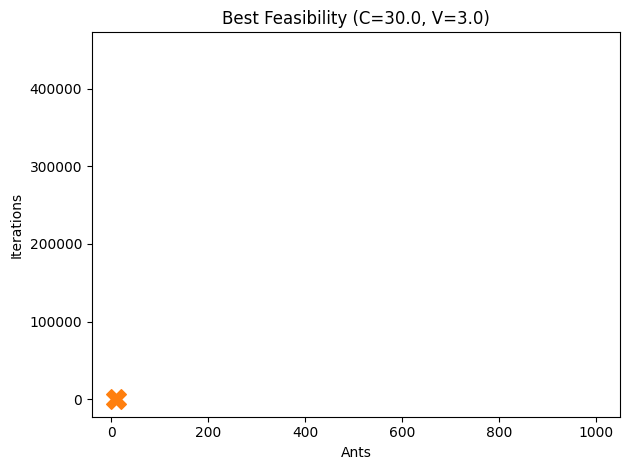

C=30.0, V=3.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


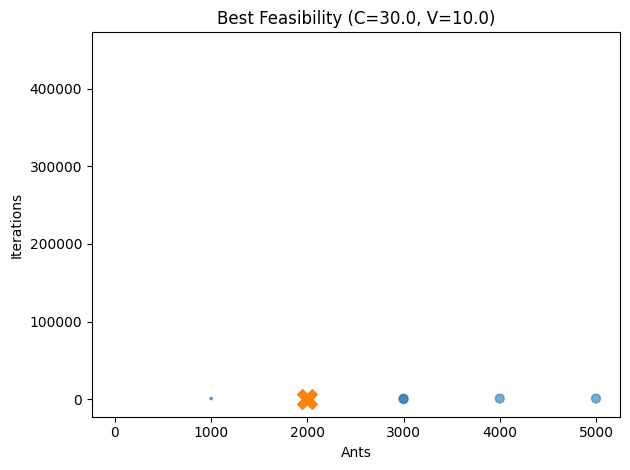

C=30.0, V=10.0
Best ants: 2000.0
Best it: 1000.0
Feasibility: 0.2
----------------------------------------


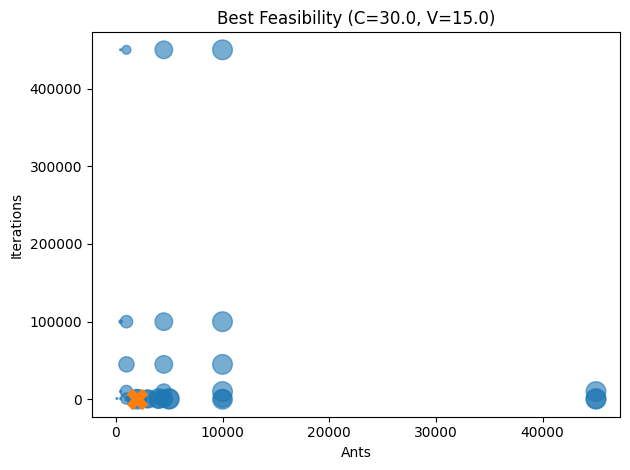

C=30.0, V=15.0
Best ants: 2000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


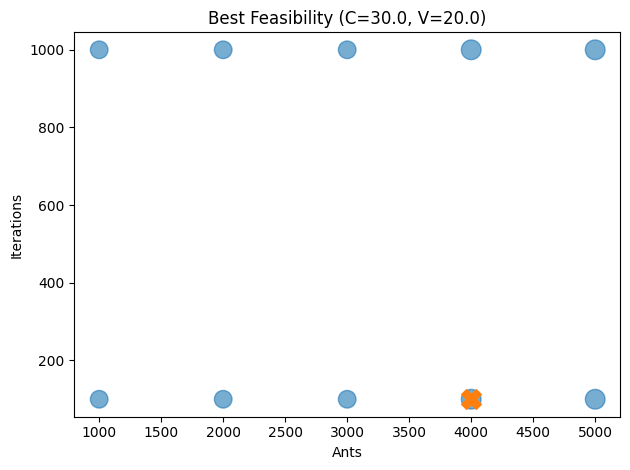

C=30.0, V=20.0
Best ants: 4000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


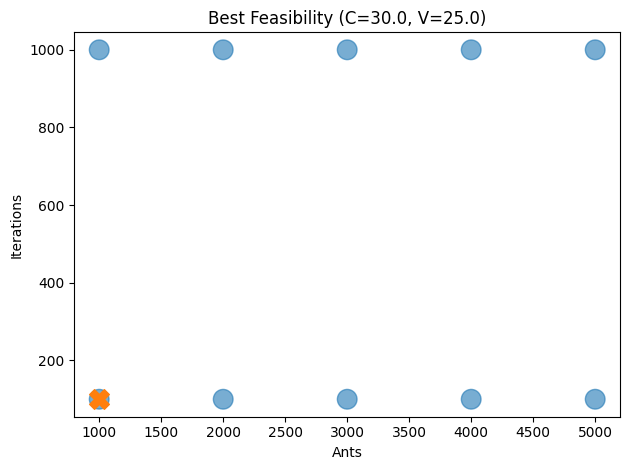

C=30.0, V=25.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


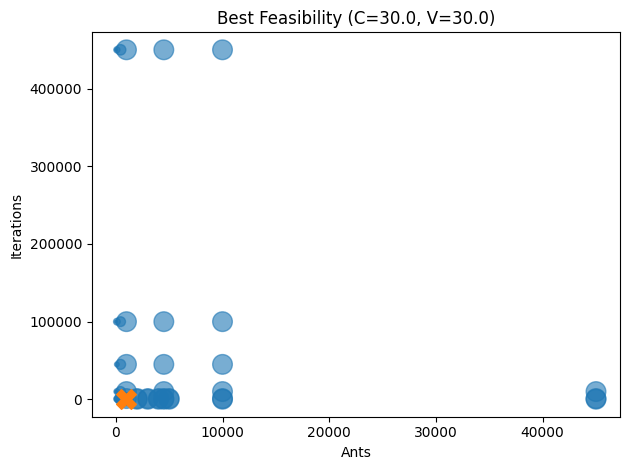

C=30.0, V=30.0
Best ants: 1000.0
Best it: 1000.0
Feasibility: 1.0
----------------------------------------


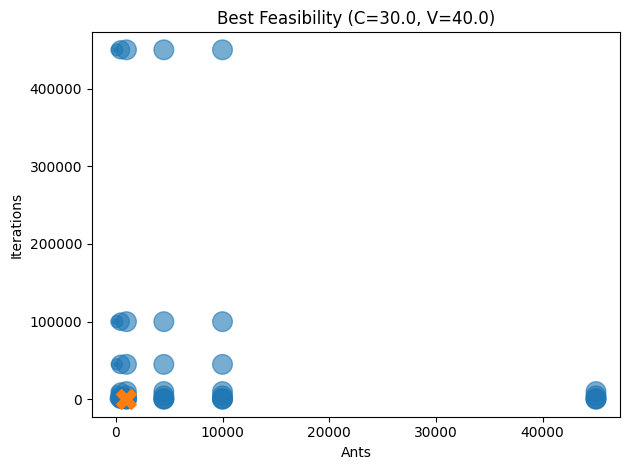

C=30.0, V=40.0
Best ants: 1000.0
Best it: 1000.0
Feasibility: 1.0
----------------------------------------


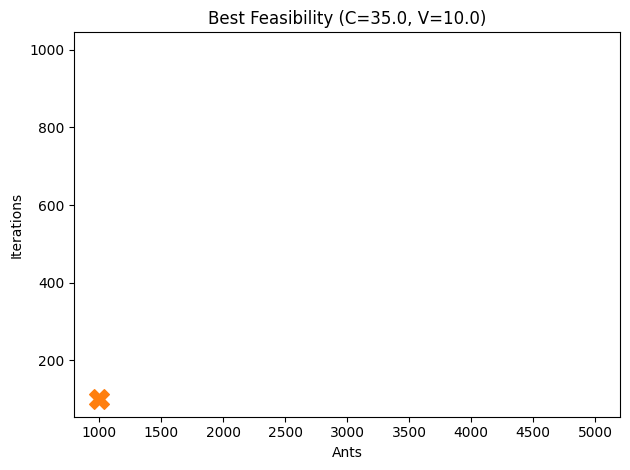

C=35.0, V=10.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


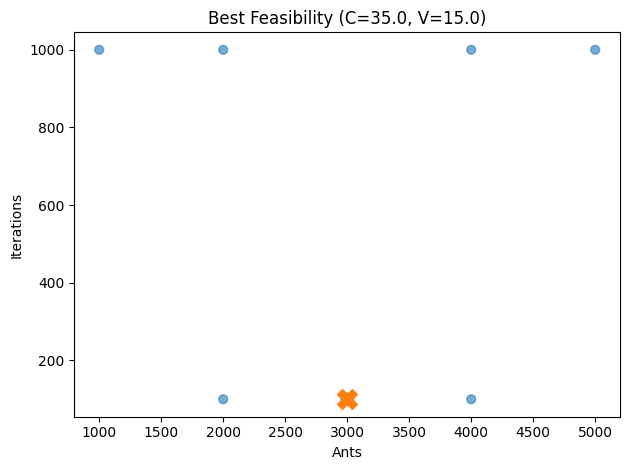

C=35.0, V=15.0
Best ants: 3000.0
Best it: 100.0
Feasibility: 0.4
----------------------------------------


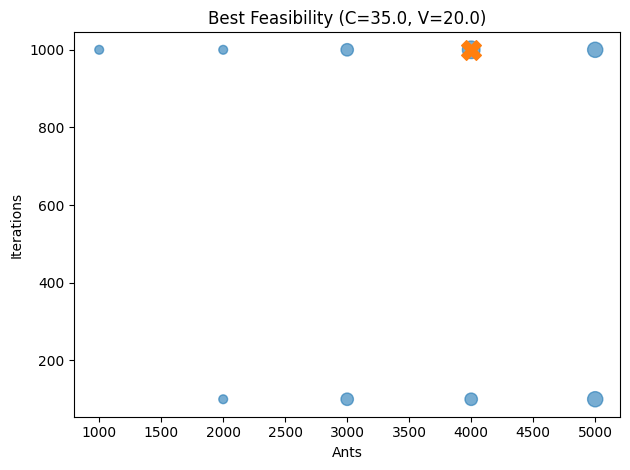

C=35.0, V=20.0
Best ants: 4000.0
Best it: 1000.0
Feasibility: 0.8
----------------------------------------


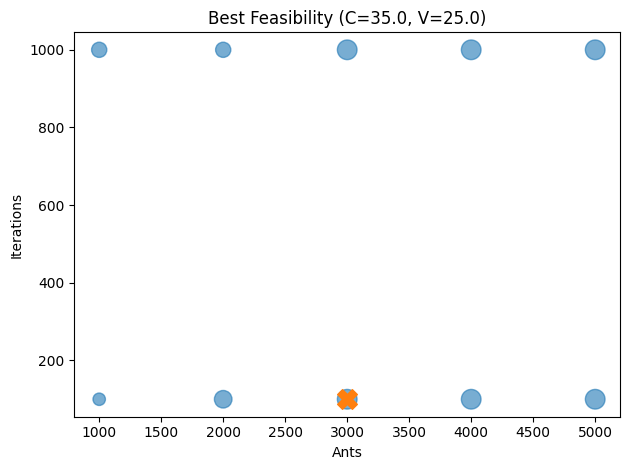

C=35.0, V=25.0
Best ants: 3000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


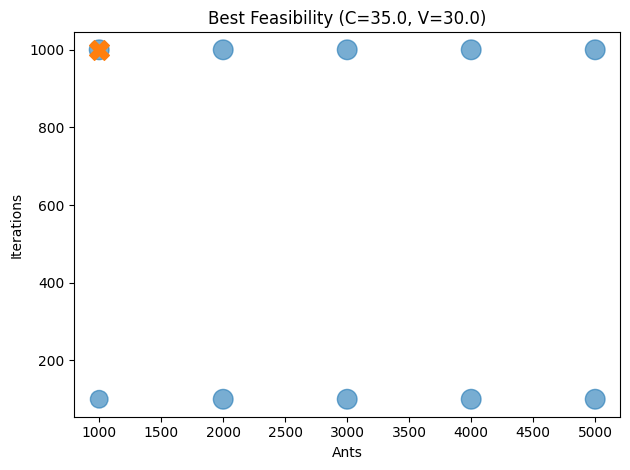

C=35.0, V=30.0
Best ants: 1000.0
Best it: 1000.0
Feasibility: 1.0
----------------------------------------


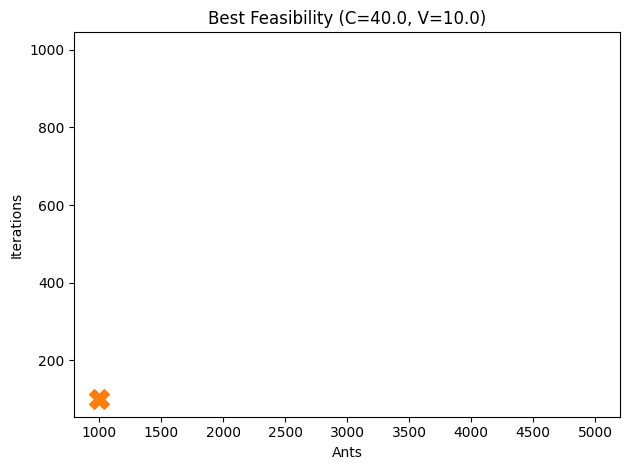

C=40.0, V=10.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


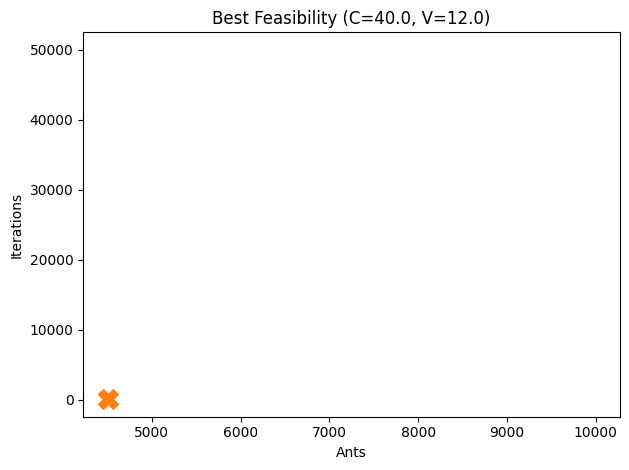

C=40.0, V=12.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


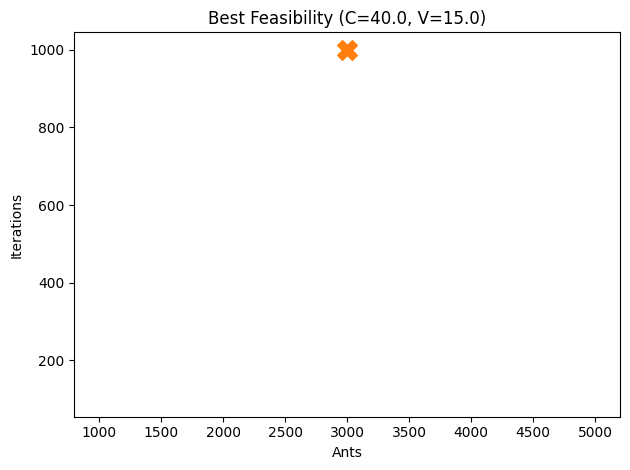

C=40.0, V=15.0
Best ants: 3000.0
Best it: 1000.0
Feasibility: 0.2
----------------------------------------


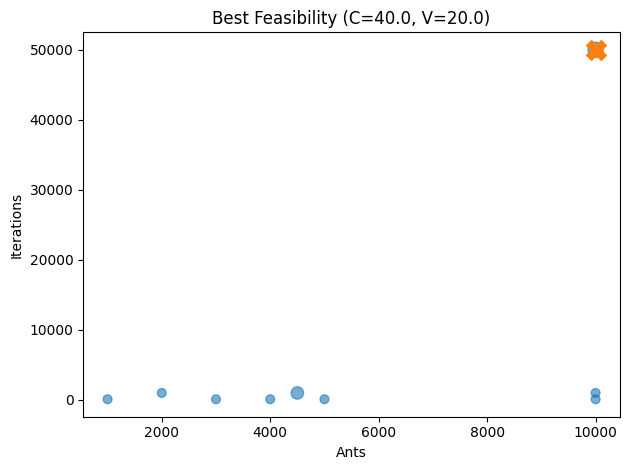

C=40.0, V=20.0
Best ants: 10000.0
Best it: 50000.0
Feasibility: 0.6
----------------------------------------


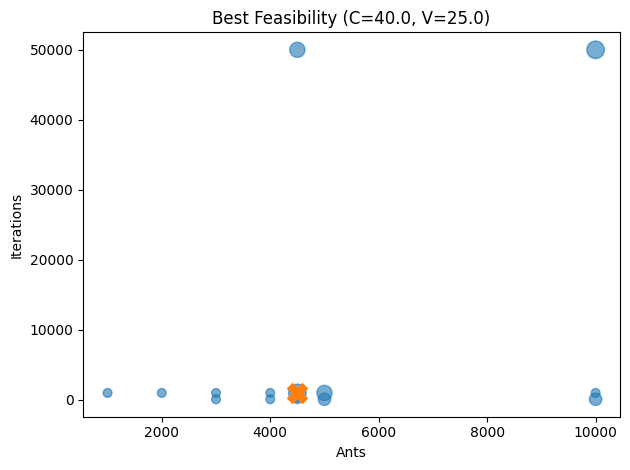

C=40.0, V=25.0
Best ants: 4500.0
Best it: 1000.0
Feasibility: 0.8
----------------------------------------


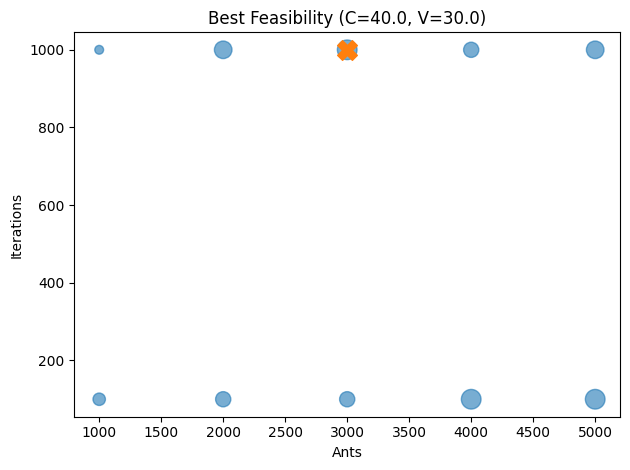

C=40.0, V=30.0
Best ants: 3000.0
Best it: 1000.0
Feasibility: 1.0
----------------------------------------


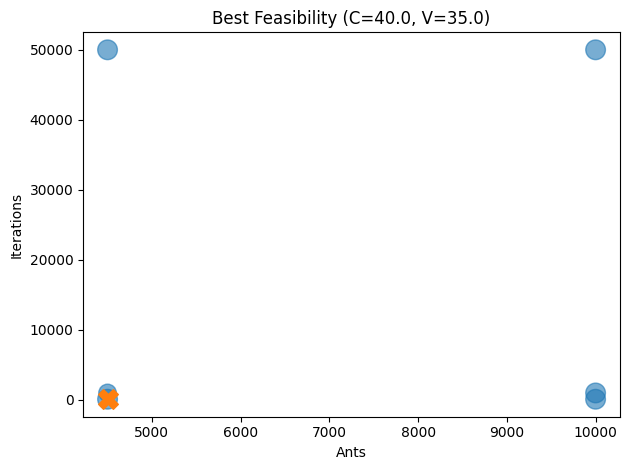

C=40.0, V=35.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


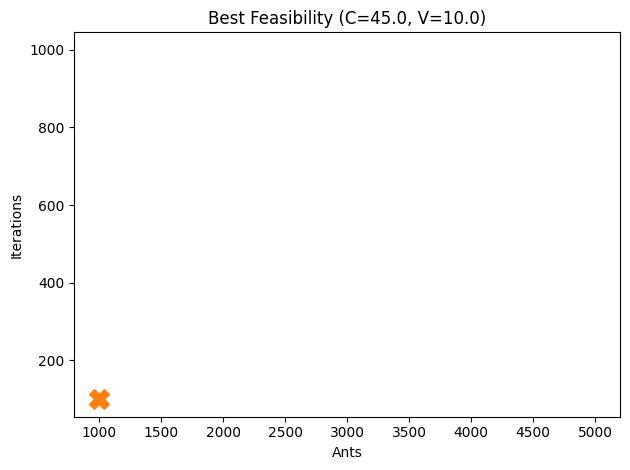

C=45.0, V=10.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


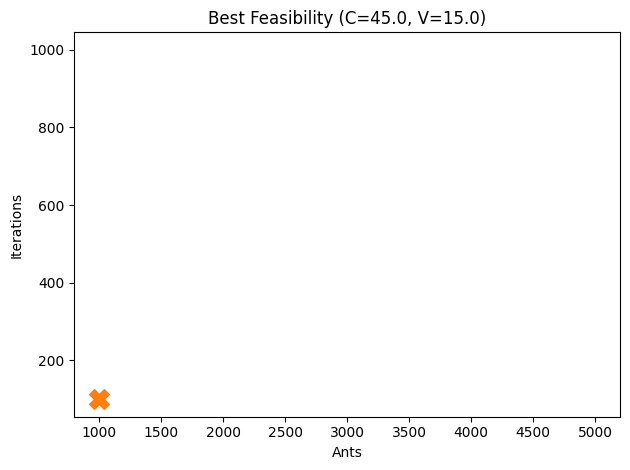

C=45.0, V=15.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


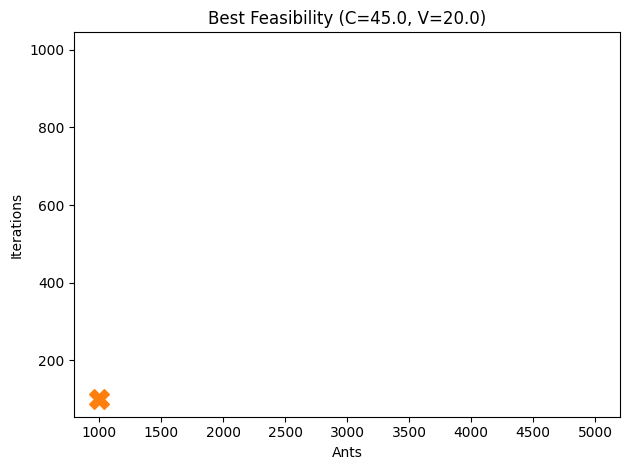

C=45.0, V=20.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


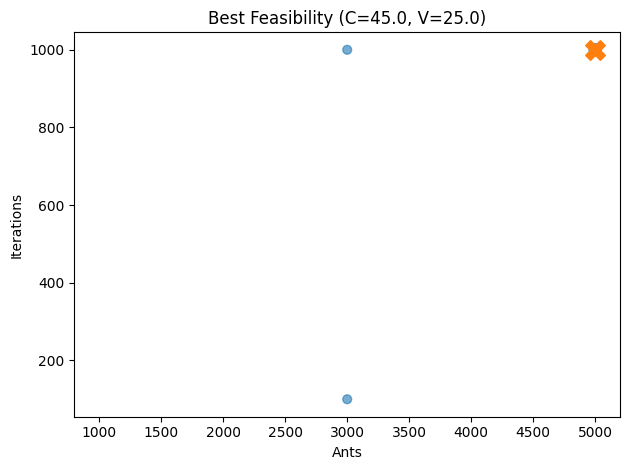

C=45.0, V=25.0
Best ants: 5000.0
Best it: 1000.0
Feasibility: 0.4
----------------------------------------


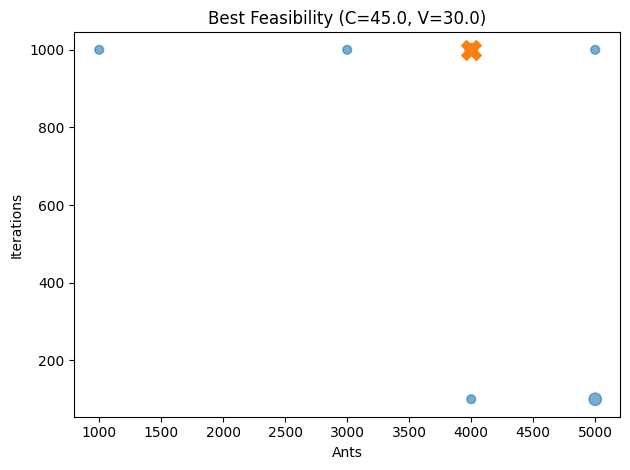

C=45.0, V=30.0
Best ants: 4000.0
Best it: 1000.0
Feasibility: 0.4
----------------------------------------


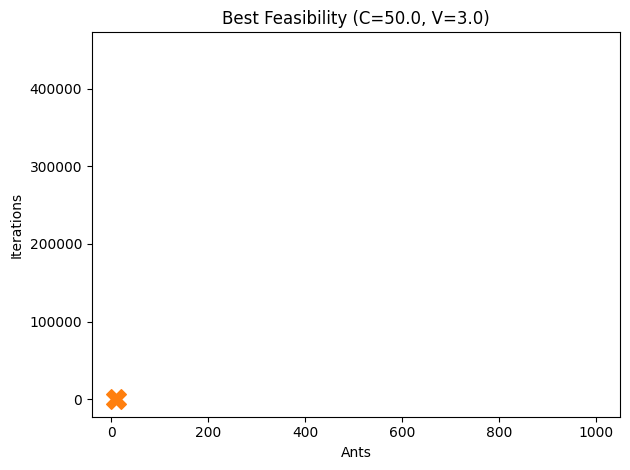

C=50.0, V=3.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


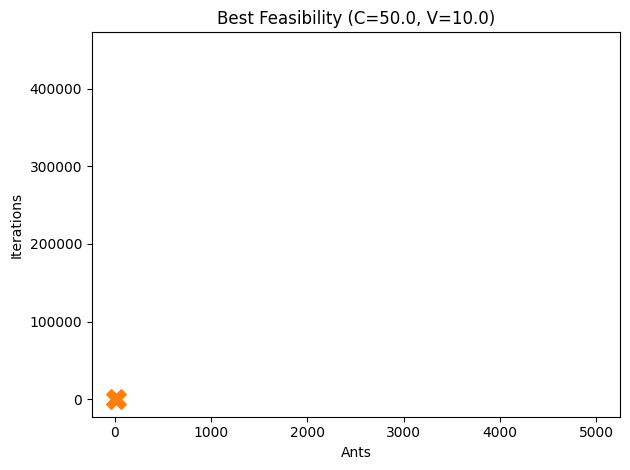

C=50.0, V=10.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


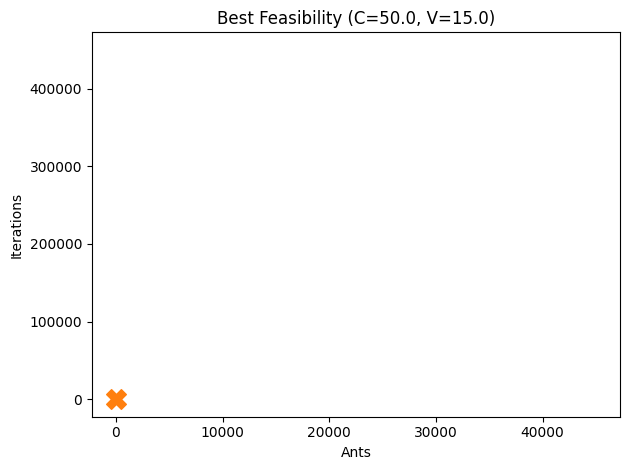

C=50.0, V=15.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


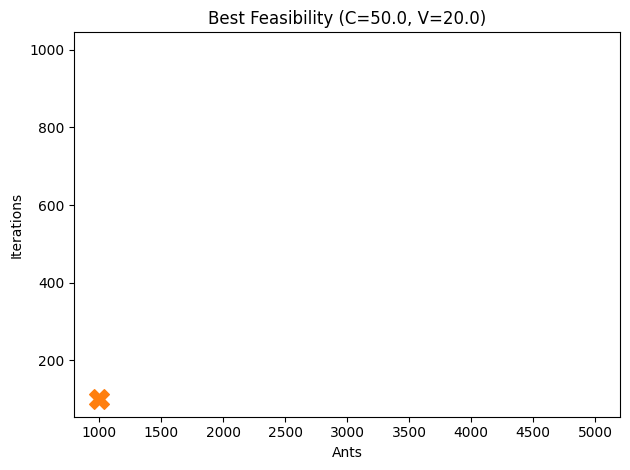

C=50.0, V=20.0
Best ants: 1000.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


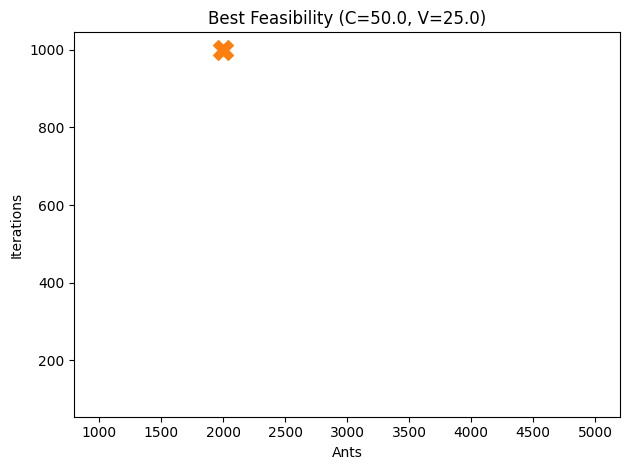

C=50.0, V=25.0
Best ants: 2000.0
Best it: 1000.0
Feasibility: 0.2
----------------------------------------


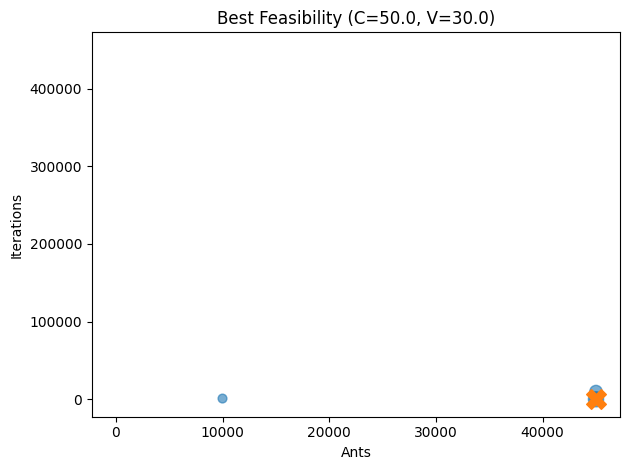

C=50.0, V=30.0
Best ants: 45000.0
Best it: 100.0
Feasibility: 0.6
----------------------------------------


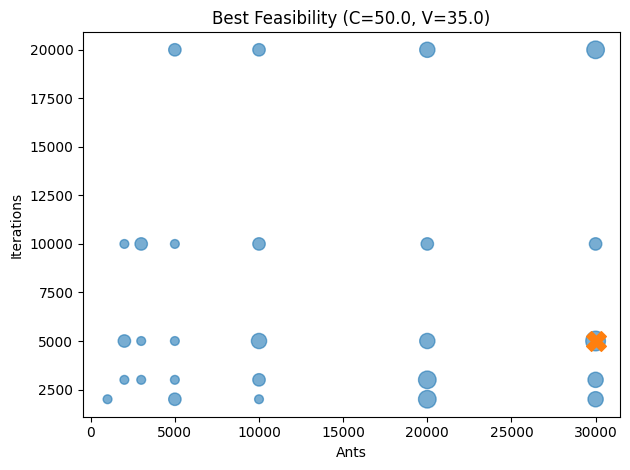

C=50.0, V=35.0
Best ants: 30000.0
Best it: 5000.0
Feasibility: 1.0
----------------------------------------


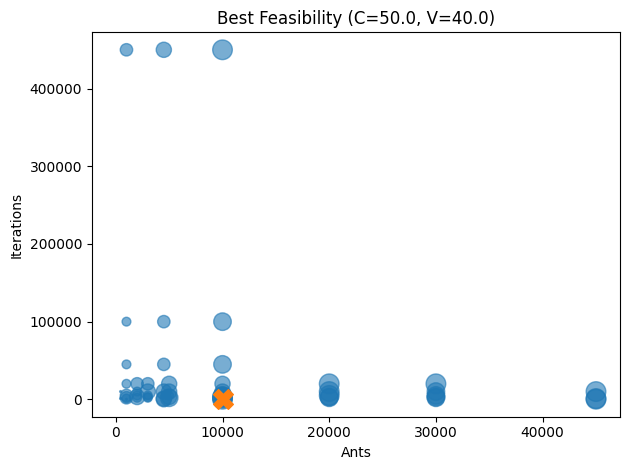

C=50.0, V=40.0
Best ants: 10000.0
Best it: 100.0
Feasibility: 1.0
----------------------------------------


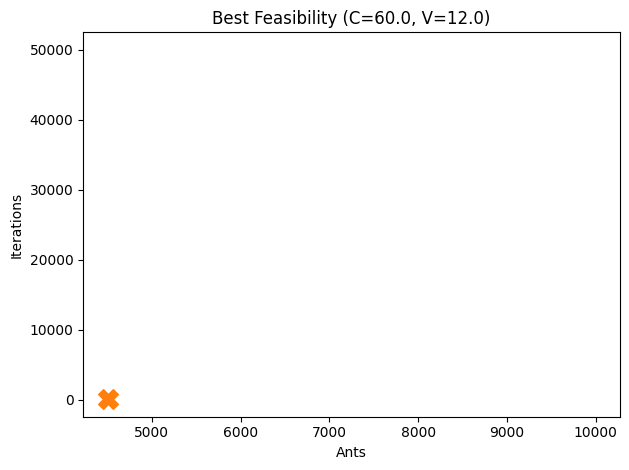

C=60.0, V=12.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


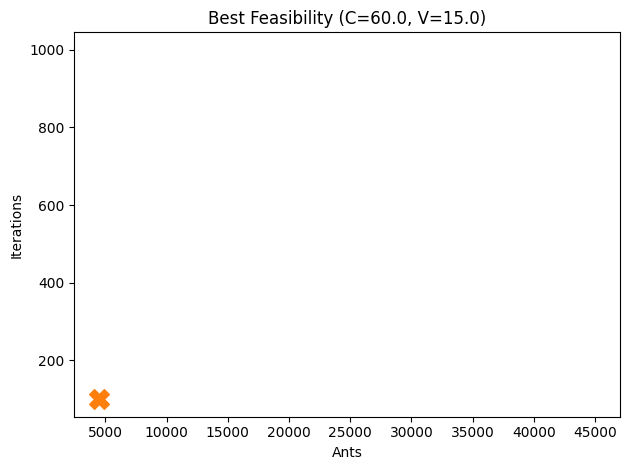

C=60.0, V=15.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


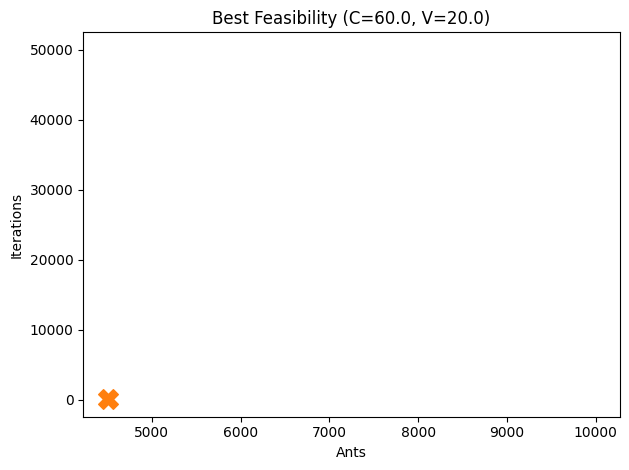

C=60.0, V=20.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


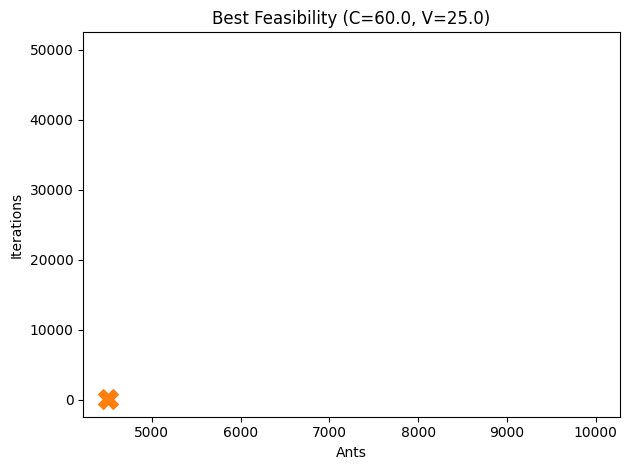

C=60.0, V=25.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


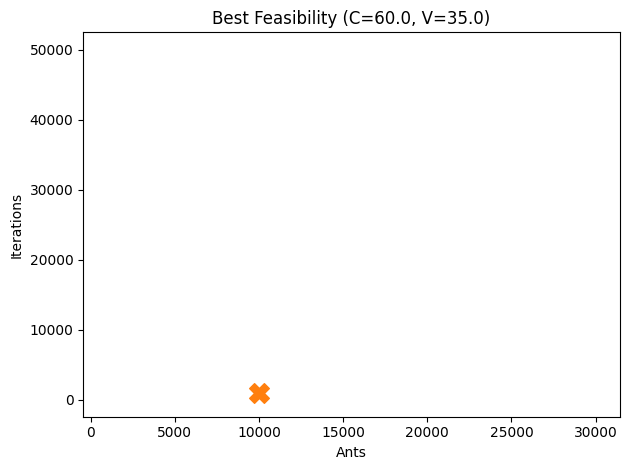

C=60.0, V=35.0
Best ants: 10000.0
Best it: 1000.0
Feasibility: 0.2
----------------------------------------


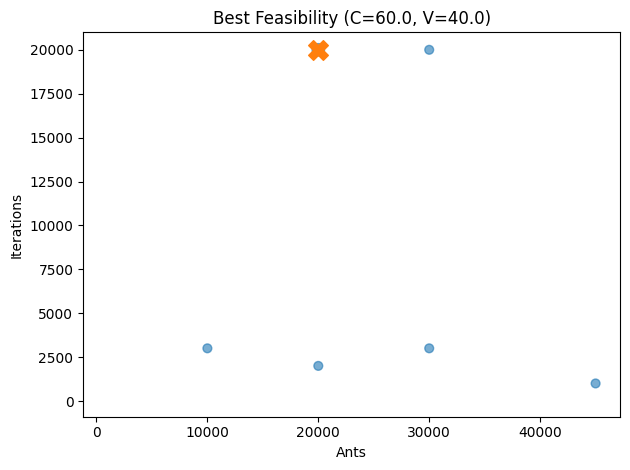

C=60.0, V=40.0
Best ants: 20000.0
Best it: 20000.0
Feasibility: 0.4
----------------------------------------


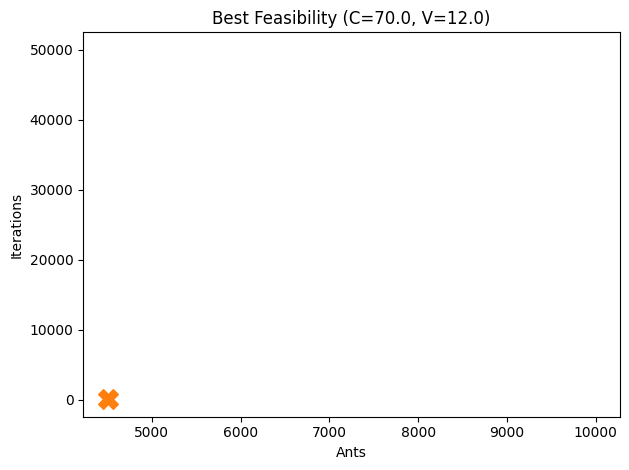

C=70.0, V=12.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


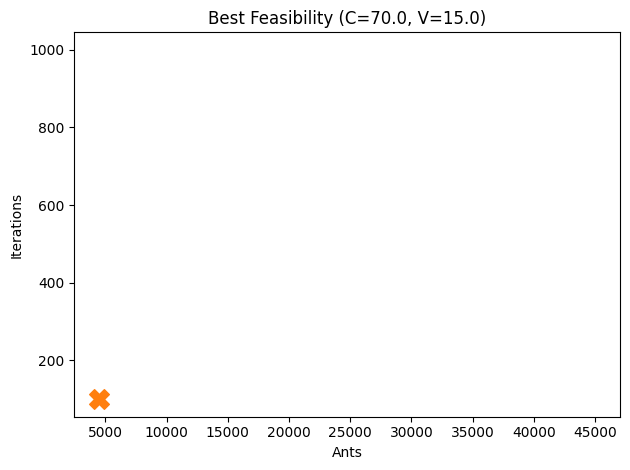

C=70.0, V=15.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


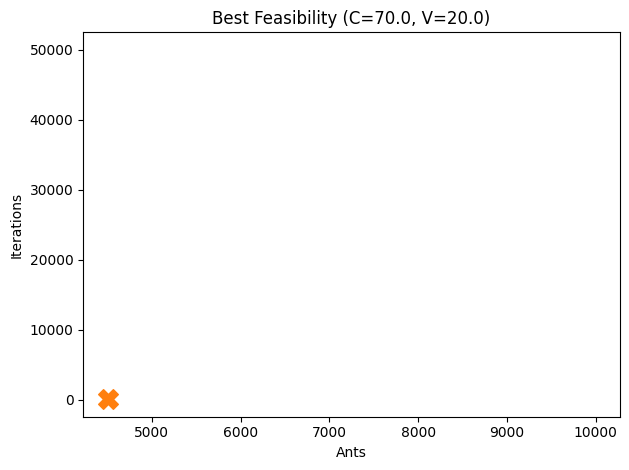

C=70.0, V=20.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


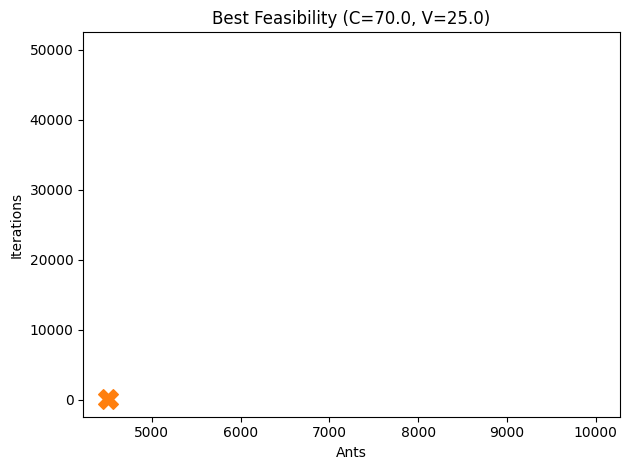

C=70.0, V=25.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


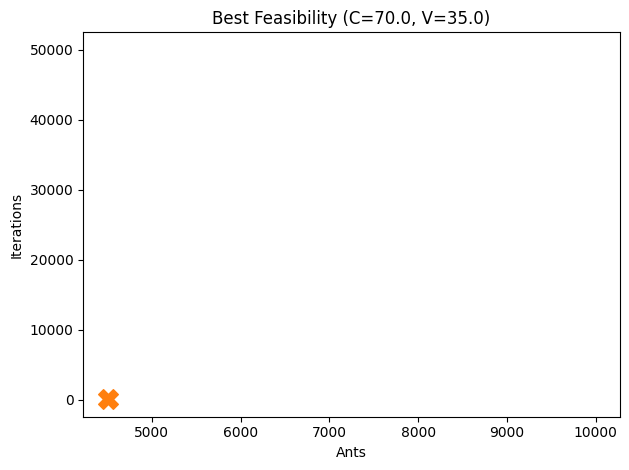

C=70.0, V=35.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


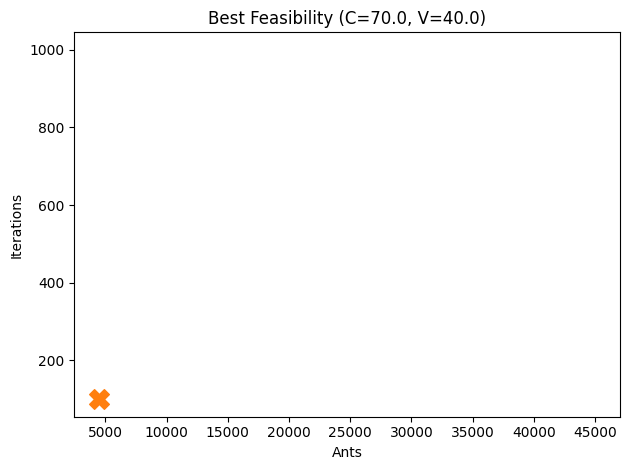

C=70.0, V=40.0
Best ants: 4500.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


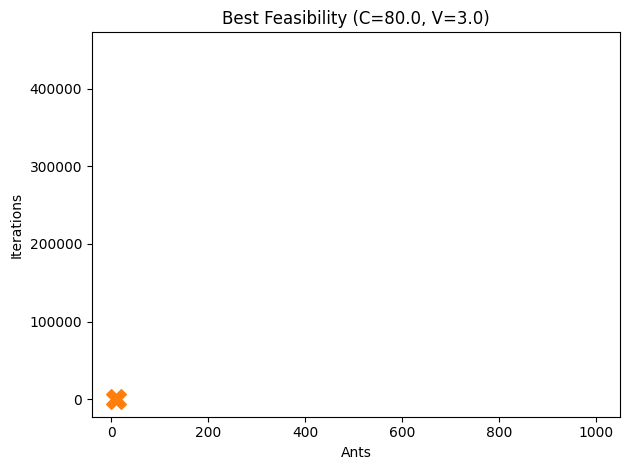

C=80.0, V=3.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


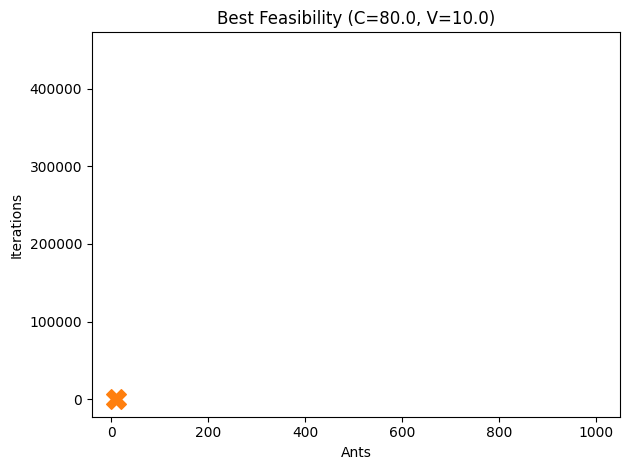

C=80.0, V=10.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


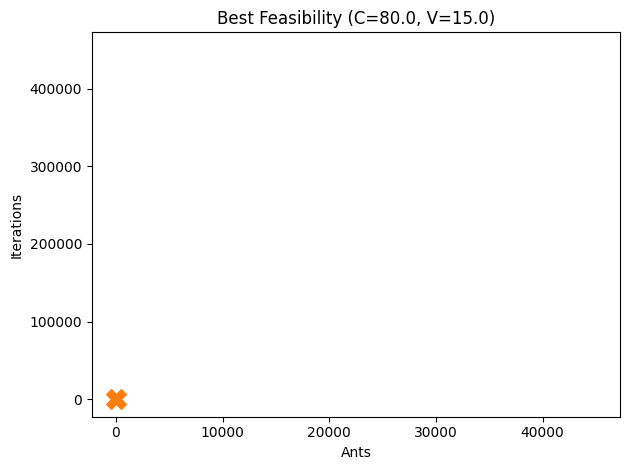

C=80.0, V=15.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


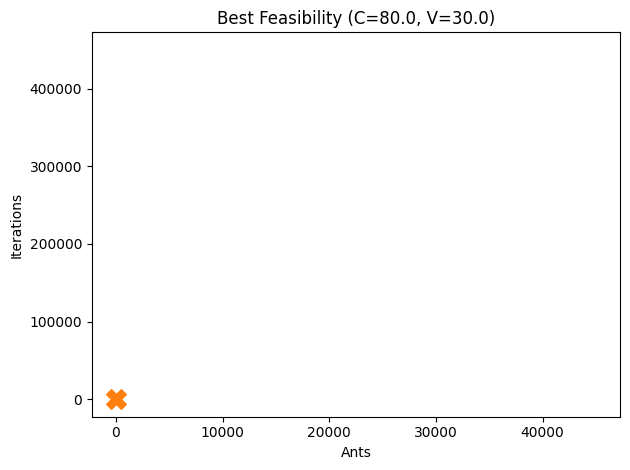

C=80.0, V=30.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


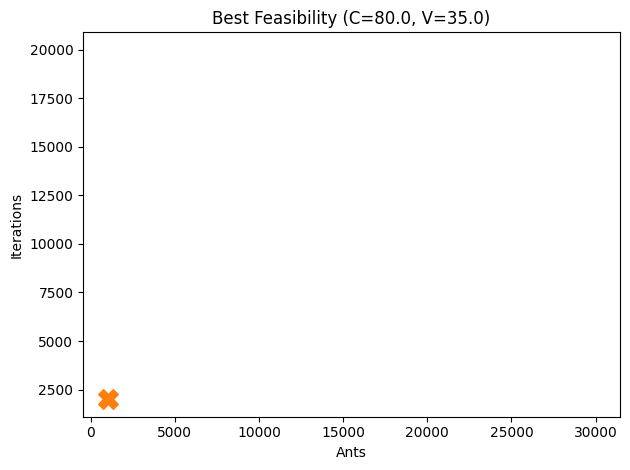

C=80.0, V=35.0
Best ants: 1000.0
Best it: 2000.0
Feasibility: 0.0
----------------------------------------


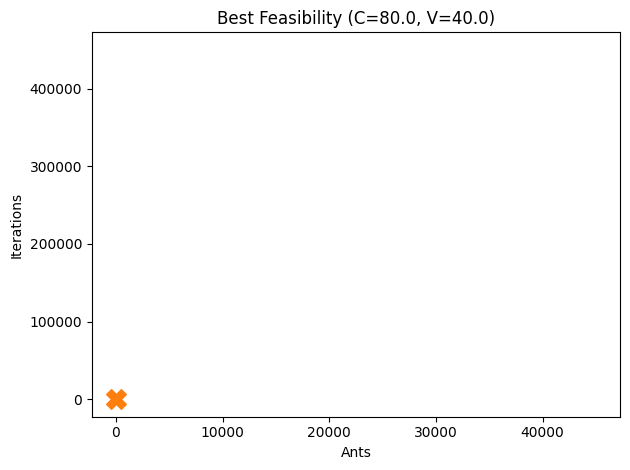

C=80.0, V=40.0
Best ants: 10.0
Best it: 100.0
Feasibility: 0.0
----------------------------------------


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_best_feasibility_by_cv(df: pd.DataFrame):

    cv_pairs = (
        df[["c", "v"]]
        .drop_duplicates()
        .sort_values(["c", "v"])
        .values
    )

    for c_val, v_val in cv_pairs:

        df_cv = df[(df["c"] == c_val) & (df["v"] == v_val)].copy()

        if df_cv.empty:
            continue

        # Promedio de factibilidad por (ants, it)
        summary = (
            df_cv
            .groupby(["ants", "it"])["feasible"]
            .mean()
            .reset_index()
        )

        # Encontrar mejor combinación
        best_row = summary.loc[summary["feasible"].idxmax()]

        # Plot
        plt.figure()

        plt.scatter(summary["ants"], summary["it"],
                    s=summary["feasible"] * 200,
                    alpha=0.6)

        plt.scatter(best_row["ants"], best_row["it"],
                    marker="X", s=200)

        plt.title(f"Best Feasibility (C={c_val}, V={v_val})")
        plt.xlabel("Ants")
        plt.ylabel("Iterations")

        plt.tight_layout()
        plt.show()

        print(f"C={c_val}, V={v_val}")
        print("Best ants:", best_row["ants"])
        print("Best it:", best_row["it"])
        print("Feasibility:", best_row["feasible"])
        print("-" * 40)
plot_best_feasibility_by_cv(df)

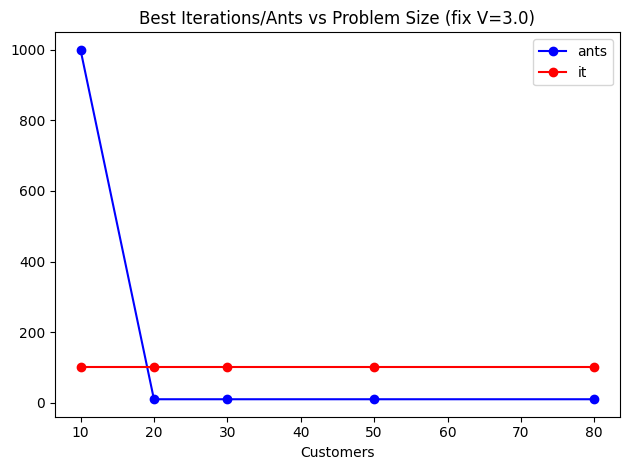

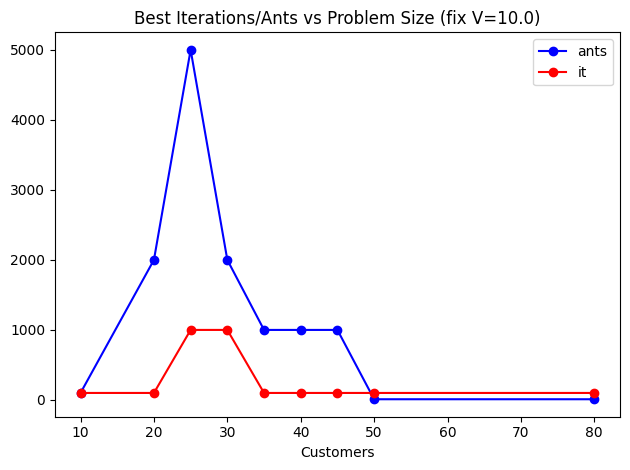

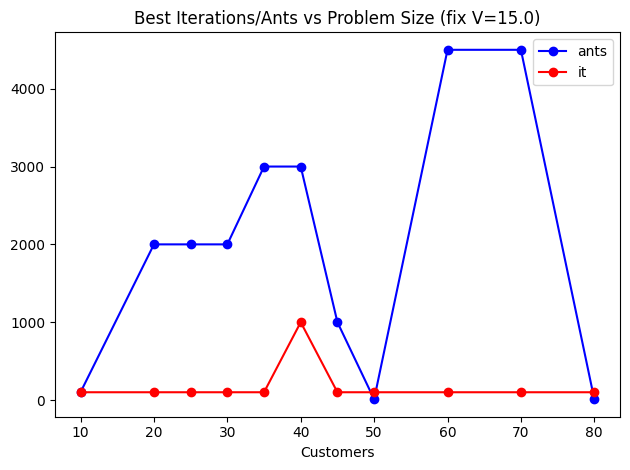

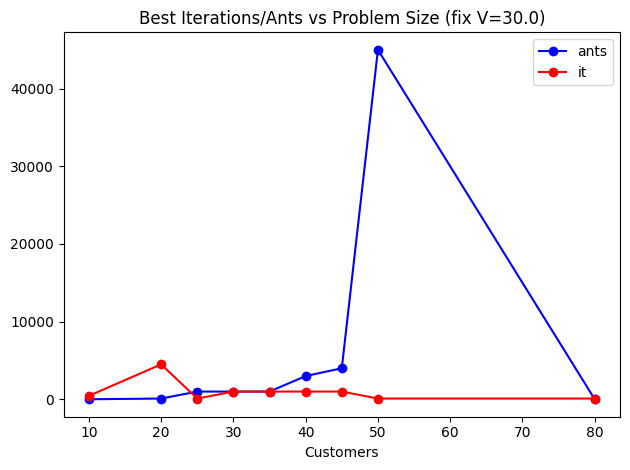

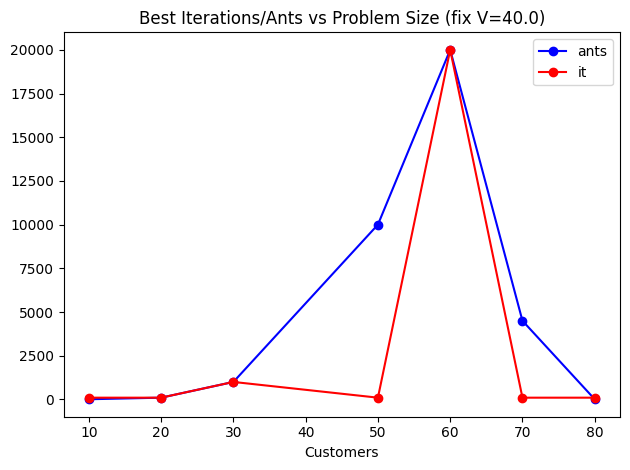

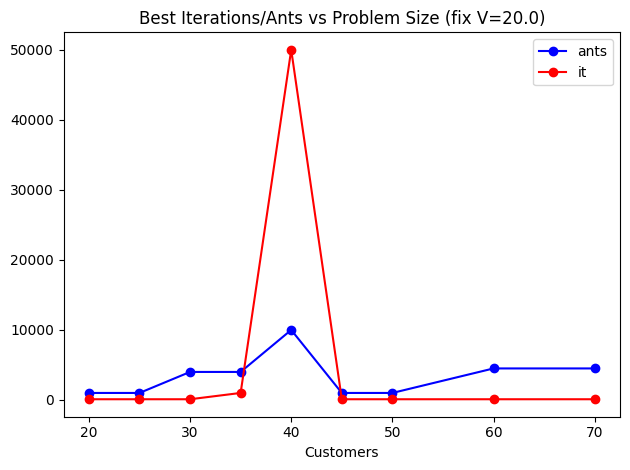

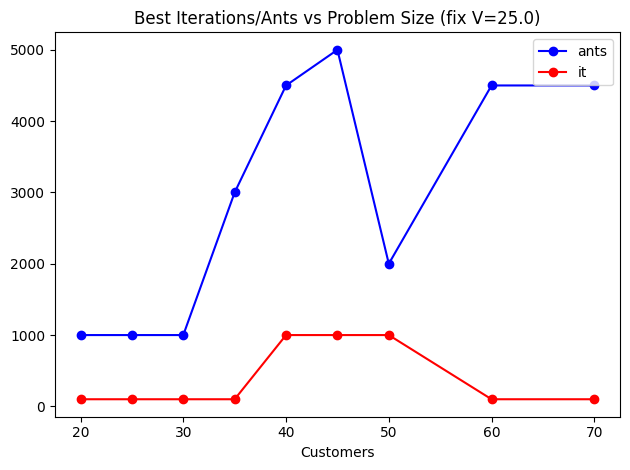

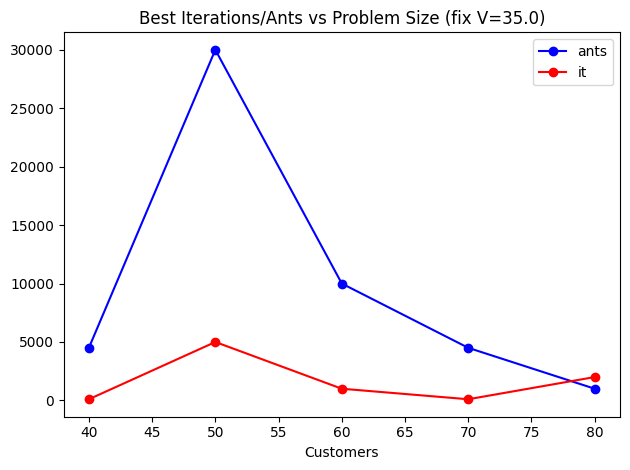

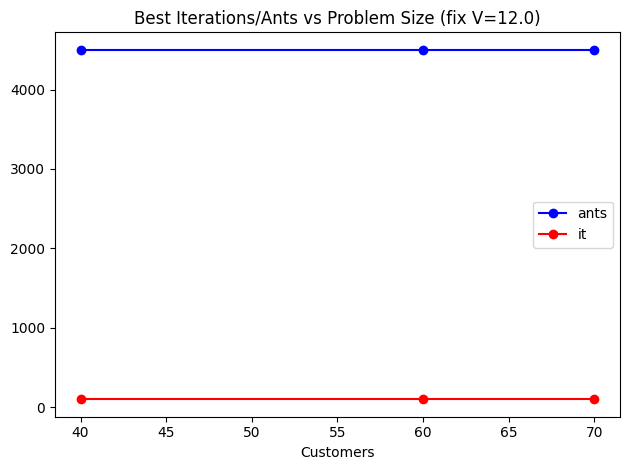

In [13]:
def compute_best_configs(df: pd.DataFrame):

    best_configs = []

    # Iteramos por cada combinación de customers y vehicles
    for (c_val, v_val), group in df.groupby(["c", "v"]):

        # Promedio de factibilidad por (ants, it)
        summary = (
            group
            .groupby(["ants", "it"])["feasible"]
            .mean()
            .reset_index()
        )

        # Mejor combinación
        best_row = summary.loc[summary["feasible"].idxmax()]

        best_configs.append({
            "c": c_val,
            "v": v_val,
            "problem_size": c_val,  # usamos customers como escala principal
            "best_ants": best_row["ants"],
            "best_it": best_row["it"],
            "feasibility": best_row["feasible"]
        })

    best_df = pd.DataFrame(best_configs)

    # Ordenamos por tamaño creciente
    best_df = best_df.sort_values("problem_size")

    return best_df

def plot_scaling_behavior(best_df: pd.DataFrame, v: int):

    plt.figure()
    plt.plot(best_df["problem_size"], best_df["best_ants"], marker="o", color='blue', label="ants")
    plt.plot(best_df["problem_size"], best_df["best_it"], marker="o", color='red', label="it")
    plt.xlabel("Customers")
    plt.title(f"Best Iterations/Ants vs Problem Size (fix V={v})")
    plt.tight_layout()
    plt.legend()
    plt.show()

for v in df['v'].unique():
    best_df = compute_best_configs(df[df['v'] == v])
    plot_scaling_behavior(best_df,v)


Nosotros suponemos que la relacion entre ants y customers sigue una ley de potencia. Entonces proponemos $a * c ^ \alpha$ 
- a: constante
- c: customers
- $ \alpha $ : factor de crecimiento

(de la misma forma para las iteraciones). Luego aplicamos log para bajar el exponente y nos queda una ecuacion de una recta. Luego lo que hacemos es graficar los puntos log(ants) vs log(c) y hacemos una regrecion lineal para estimar alfa (no porqwue creemos que la relacion es lineal, sino porque llevamos el problema de exponencial a lineal). y esa recta es la relacion que estoy buscando.
Si:

- Pendiente positiva (α > 0): Cuando aumentan los customers, aumentan las ants óptimas.
- Pendiente negativa (α < 0): Cuando aumentan los customers, disminuyen las ants óptimas.
- Pendiente cercana a 0: ants no depende del tamaño.

ANTS scaling:
alpha (growth exponent): 0.7730
a (scale constant): 50.9465
R^2    = 0.0331

ITERATIONS scaling:
beta (growth exponent): 0.1102
b (scale constant): 149.4493
R^2    = -0.9452


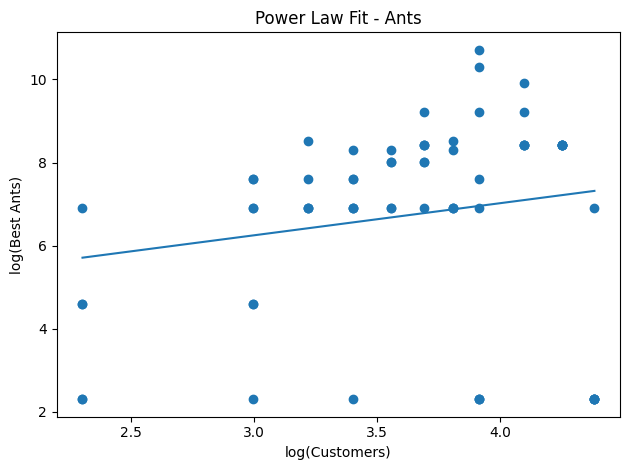

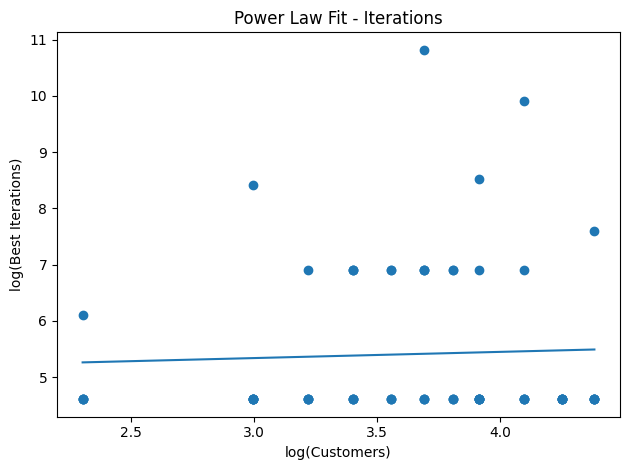

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

def fit_power_law(best_df):

    # Usamos customers como variable principal
    x = np.log(best_df["c"].values).reshape(-1, 1)
    y_ants = np.log(best_df["best_ants"].values)
    y_it = np.log(best_df["best_it"].values)

    # Modelo para ants
    model_ants = LinearRegression()
    model_ants.fit(x, y_ants)

    alpha = model_ants.coef_[0]
    log_a = model_ants.intercept_
    a = np.exp(log_a)

    # Modelo para iterations
    model_it = LinearRegression()
    model_it.fit(x, y_it)

    beta = model_it.coef_[0]
    log_b = model_it.intercept_
    b = np.exp(log_b)

    r2_ants = model_ants.score(x, y_ants)
    r2_it = model_ants.score(x, y_it)
    print("ANTS scaling:")
    print(f"alpha (growth exponent): {alpha:.4f}")
    print(f"a (scale constant): {a:.4f}")
    print(f"R^2    = {r2_ants:.4f}")
    print()
    print("ITERATIONS scaling:")
    print(f"beta (growth exponent): {beta:.4f}")
    print(f"b (scale constant): {b:.4f}")
    print(f"R^2    = {r2_it:.4f}")
    
    return model_ants, model_it

def plot_log_log(best_df, model_ants, model_it):

    x_log = np.log(best_df["c"].values).reshape(-1, 1)

    # Predicciones
    pred_ants = model_ants.predict(x_log)
    pred_it = model_it.predict(x_log)

    # --- ANTS ---
    plt.figure()
    plt.scatter(np.log(best_df["c"]), np.log(best_df["best_ants"]))
    plt.plot(np.log(best_df["c"]), pred_ants)
    plt.xlabel("log(Customers)")
    plt.ylabel("log(Best Ants)")
    plt.title("Power Law Fit - Ants")
    plt.tight_layout()
    plt.show()

    # --- ITERATIONS ---
    plt.figure()
    plt.scatter(np.log(best_df["c"]), np.log(best_df["best_it"]))
    plt.plot(np.log(best_df["c"]), pred_it)
    plt.xlabel("log(Customers)")
    plt.ylabel("log(Best Iterations)")
    plt.title("Power Law Fit - Iterations")
    plt.tight_layout()
    plt.show()
best_df = compute_best_configs(df)

model_ants, model_it = fit_power_law(best_df)

plot_log_log(best_df, model_ants, model_it)


Una primera aproximacion es postular una recta para los dos parametros. Pero sabemos bien que el problema no depende de parametros individuales, sino que hay una relacion entre los customers, los vehiculos y el tamano del problema.

Model: ants = a * c^alpha * v^gamma
a      = 2.7669
alpha  = 0.5737  (influence of customers)
gamma  = 1.2579  (influence of vehicles)
R^2    = 0.1588


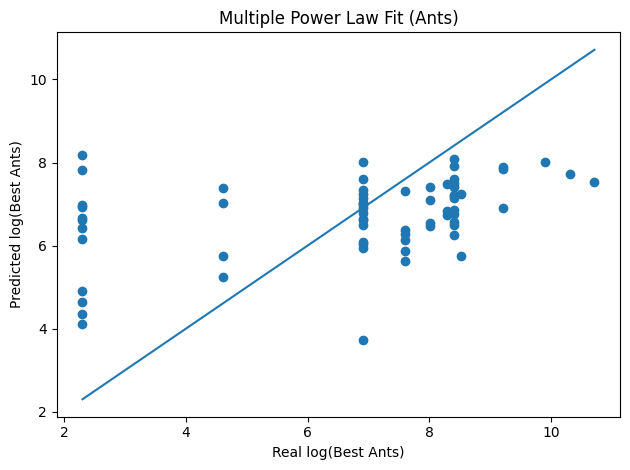

In [15]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

def fit_multiple_power_law(best_df):

    # Variables independientes (log transformadas)
    X = np.column_stack([
        np.log(best_df["c"].values),
        np.log(best_df["v"].values)
    ])

    # Variable dependiente
    y = np.log(best_df["best_ants"].values)

    model = LinearRegression()
    model.fit(X, y)

    alpha = model.coef_[0]   # exponente para c
    gamma = model.coef_[1]   # exponente para v
    log_a = model.intercept_
    a = np.exp(log_a)

    r2 = model.score(X, y)

    print("Model: ants = a * c^alpha * v^gamma")
    print(f"a      = {a:.4f}")
    print(f"alpha  = {alpha:.4f}  (influence of customers)")
    print(f"gamma  = {gamma:.4f}  (influence of vehicles)")
    print(f"R^2    = {r2:.4f}")

    return model


def plot_multiple_fit(best_df, model):

    # Construimos X nuevamente
    X = np.column_stack([
        np.log(best_df["c"].values),
        np.log(best_df["v"].values)
    ])

    # Valores reales
    y_real = np.log(best_df["best_ants"].values)

    # Valores predichos
    y_pred = model.predict(X)

    plt.figure()
    plt.scatter(y_real, y_pred)

    # Línea ideal y = x
    min_val = min(y_real.min(), y_pred.min())
    max_val = max(y_real.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val])

    plt.xlabel("Real log(Best Ants)")
    plt.ylabel("Predicted log(Best Ants)")
    plt.title("Multiple Power Law Fit (Ants)")
    plt.tight_layout()
    plt.show()


best_df = compute_best_configs(df)
model_ants = fit_multiple_power_law(best_df)

plot_multiple_fit(best_df, model_ants)


R2 polynomial degree 2: 0.4662


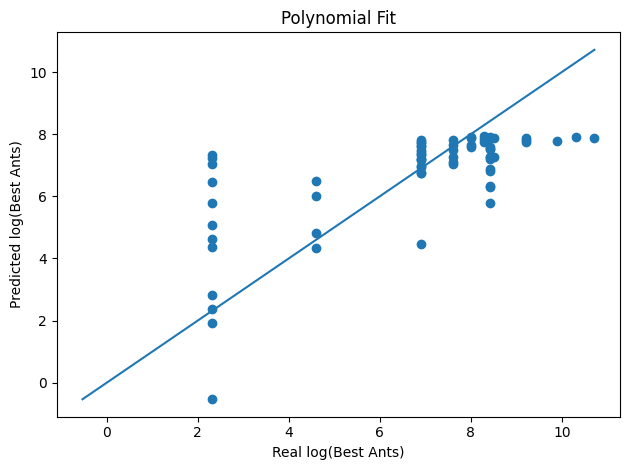

In [16]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np

def fit_polynomial_model(best_df, degree):

    # Variables en log
    X = np.column_stack([
        np.log(best_df["c"].values),
        np.log(best_df["v"].values)
    ])

    y = np.log(best_df["best_ants"].values)

    # Expandimos a polinomio
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    y_pred = model.predict(X_poly)
    r2 = r2_score(y, y_pred)

    print(f"R2 polynomial degree {degree}: {r2:.4f}")

    return model, poly
import matplotlib.pyplot as plt

def plot_polynomial_fit(best_df, model, poly):

    X = np.column_stack([
        np.log(best_df["c"].values),
        np.log(best_df["v"].values)
    ])

    X_poly = poly.transform(X)

    y_real = np.log(best_df["best_ants"].values)
    y_pred = model.predict(X_poly)

    plt.figure()
    plt.scatter(y_real, y_pred)

    min_val = min(y_real.min(), y_pred.min())
    max_val = max(y_real.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val])

    plt.xlabel("Real log(Best Ants)")
    plt.ylabel("Predicted log(Best Ants)")
    plt.title("Polynomial Fit")
    plt.tight_layout()
    plt.show()
best_df = compute_best_configs(df)

model_poly, poly = fit_polynomial_model(best_df, degree=2)

plot_polynomial_fit(best_df, model_poly, poly)


<Axes: >

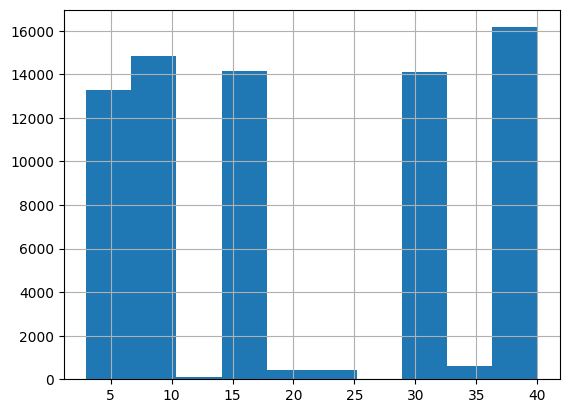

In [17]:
df['v'].hist()

<Axes: >

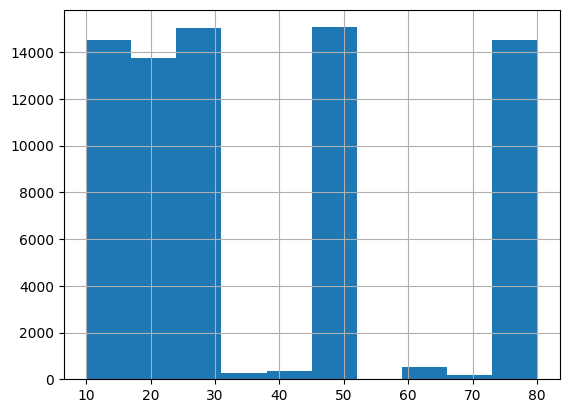

In [18]:
df['c'].hist()

<Axes: >

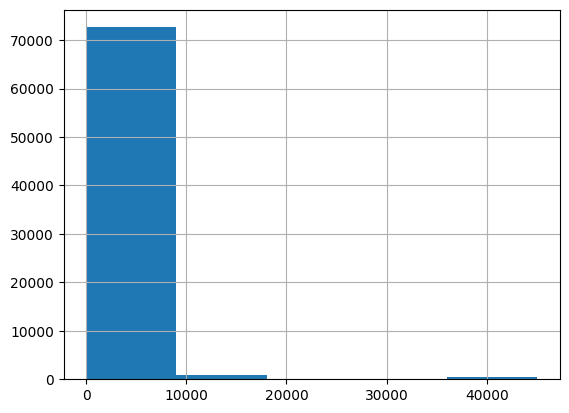

In [19]:
df['ants'].hist(bins=5)

<Axes: >

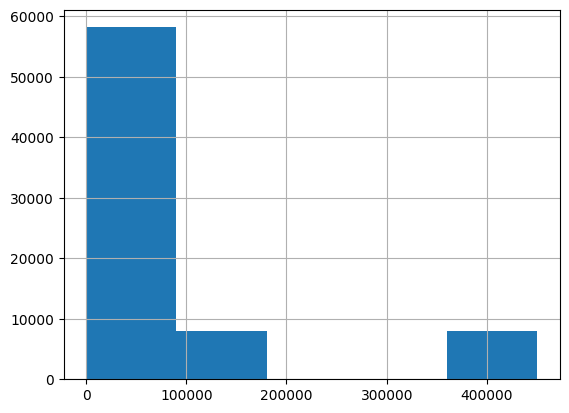

In [20]:
df['it'].hist(bins=5)

### Encaro de otra forma

Fijo instnacias puntuales, veo relacion. Despues de ver varias instancias deduzco una regla y veo si se cumple para el caso general

1. Primero veamos cuales son las convinaciones con mas ejemplos c-v y seleccionamos algunos
2. Dado las instancias fijadas del paso 1, la idea es fijar para cada v un c, teniendo en cuenta:
    - Filtramos las que tengan un rate de feasibilidad > 0.7 
    - Si no hay mucha densidad de instancias las generamos puntualmente

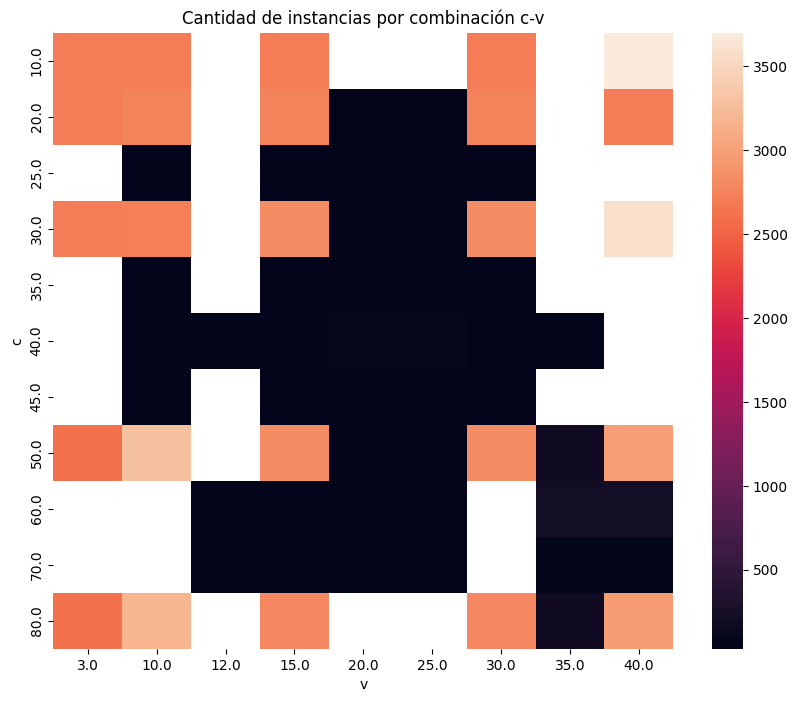

Cantidad total de filas seleccionadas: 47530


In [21]:
counts_cv = df.groupby(['c', 'v']).size().reset_index(name='count')
pivot = counts_cv.pivot(index='c', columns='v', values='count')

plt.figure(figsize=(10, 8))
sns.heatmap(pivot, annot=False)
plt.title("Cantidad de instancias por combinación c-v")
plt.xlabel("v")
plt.ylabel("c")
plt.show()

# {v: [cs]}
vc_selection = {
    10: [80, 50, 30, 10],
    15: [80, 50, 30, 20],
    30: [80, 50, 30, 20],
    40: [80, 50, 30, 10]
}


mask = False
for v, cs in vc_selection.items():
    mask |= ((df['v'] == v) & (df['c'].isin(cs)))

df_selected = df[mask].copy()

print("Cantidad total de filas seleccionadas:", len(df_selected))


In [22]:
feas_stats = (
    df_selected
    .groupby(['c', 'v', 'ants', 'it'])['feasible']
    .agg(['mean', 'count'])
    .reset_index()
)

feas_stats = feas_stats.rename(columns={
    'mean': 'feasibility_rate',
    'count': 'total_runs'
})

feas_good = feas_stats[feas_stats['feasibility_rate'] >= 0.7]

(v=10, c=80) -> sin datos
(v=10, c=50) -> sin datos
(v=10, c=30) -> sin datos


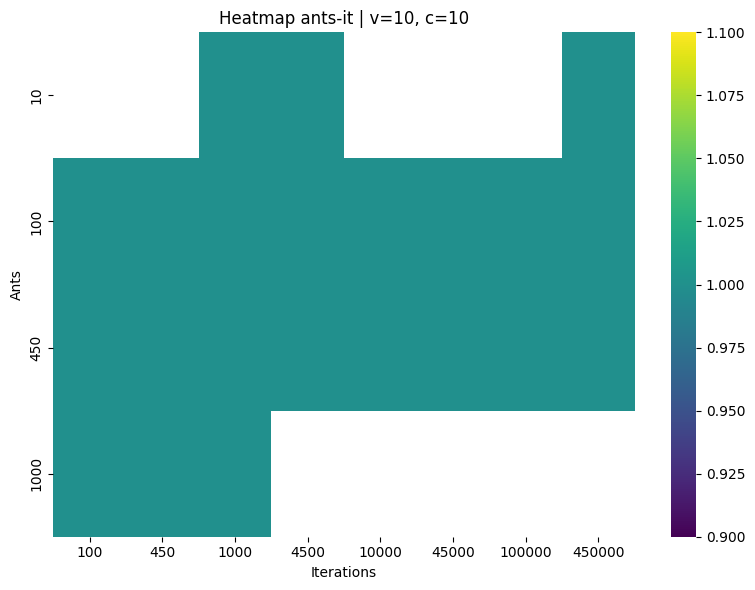

(v=15, c=80) -> sin datos
(v=15, c=50) -> sin datos


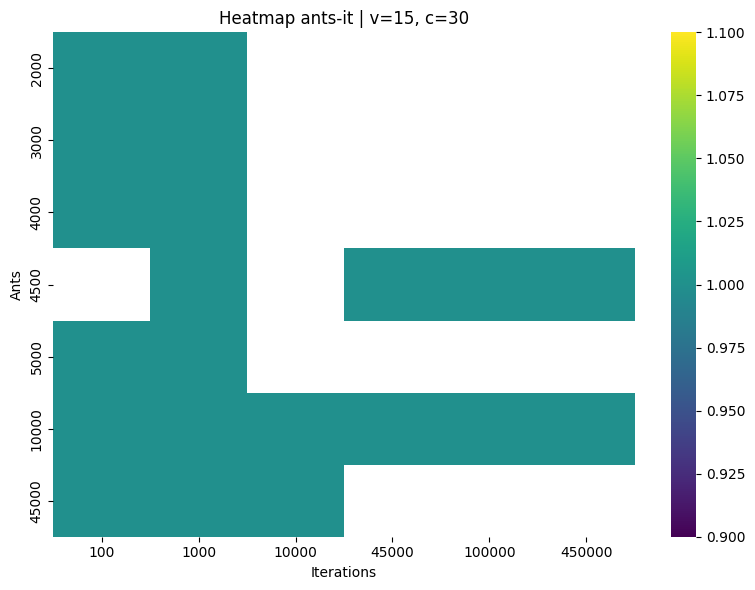

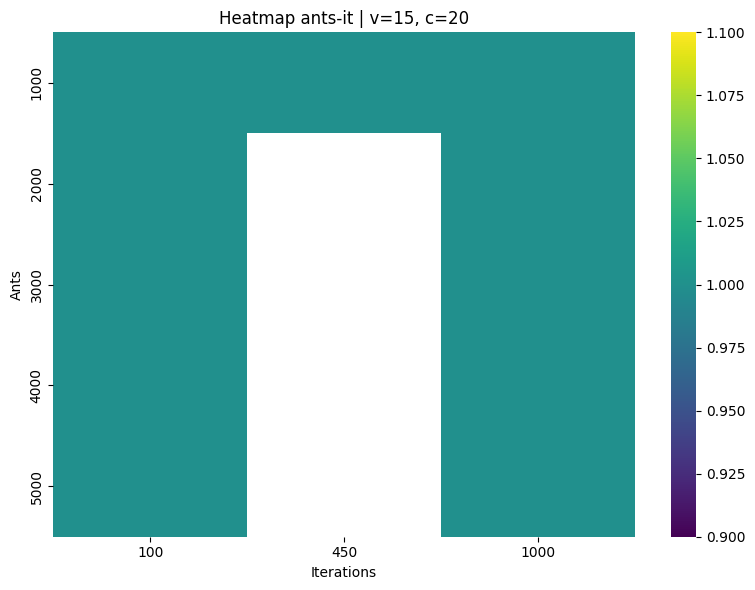

(v=30, c=80) -> sin datos
(v=30, c=50) -> sin datos


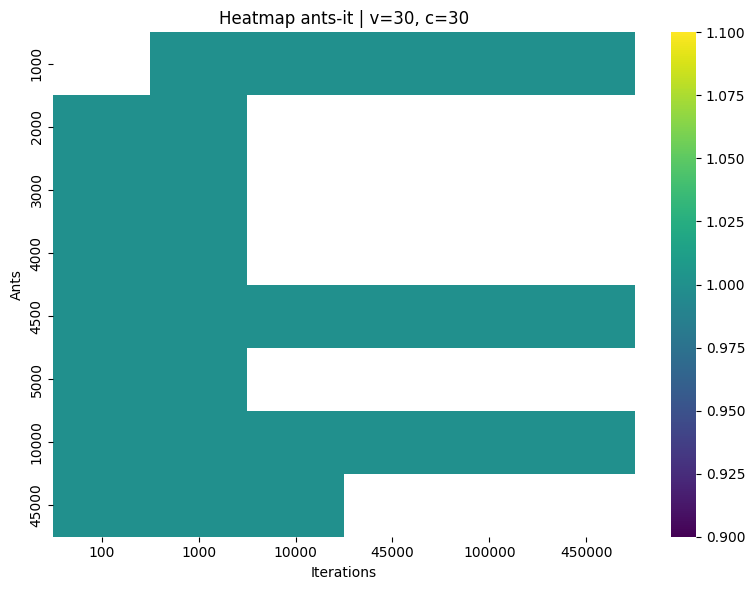

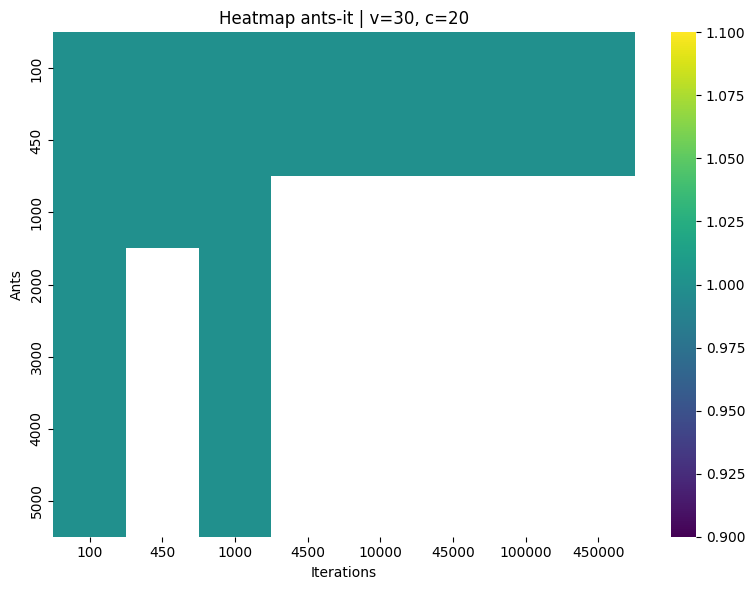

(v=40, c=80) -> sin datos


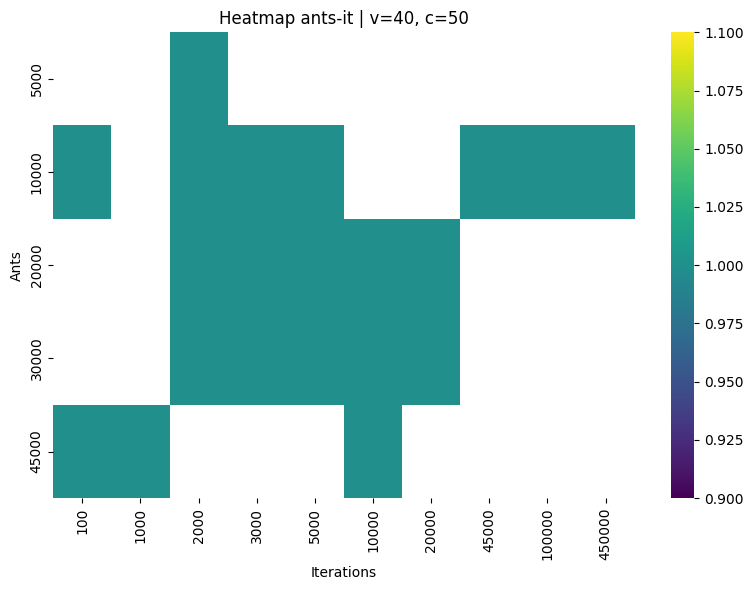

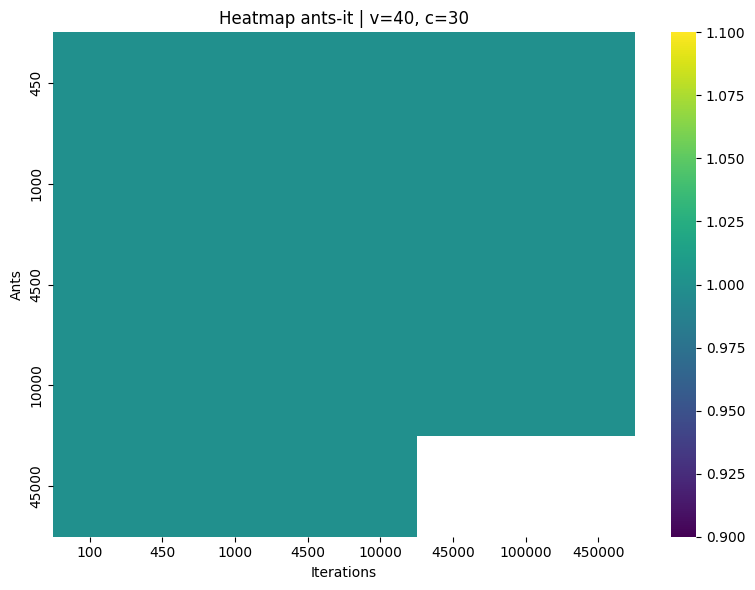

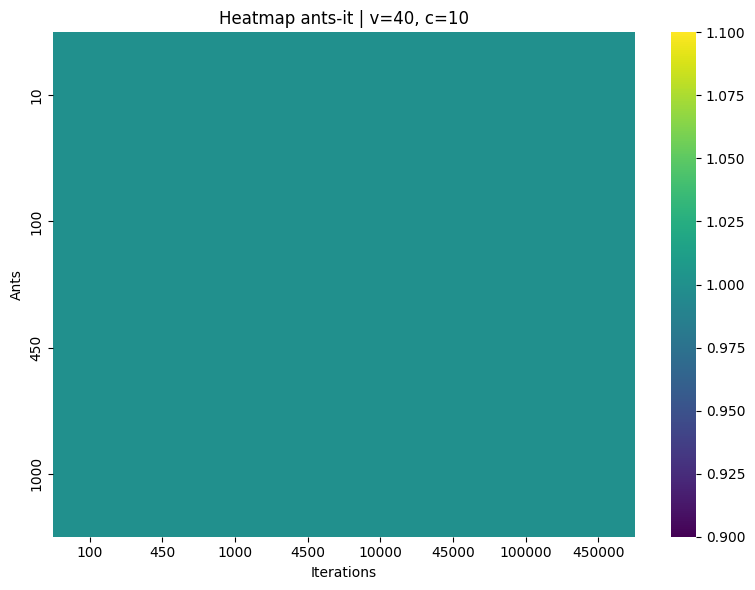

In [23]:
for v, cs in vc_selection.items():
    for c in cs:
        
        subset = feas_good[(feas_good['v'] == v) & (feas_good['c'] == c)]
        
        if subset.empty:
            print(f"(v={v}, c={c}) -> sin datos")
            continue
        
        counts = subset.groupby(['ants', 'it']).size().reset_index(name='count')
        pivot = counts.pivot(index='ants', columns='it', values='count')
        
        plt.figure(figsize=(8,6))
        sns.heatmap(pivot, cmap="viridis")
        plt.title(f"Heatmap ants-it | v={v}, c={c}")
        plt.xlabel("Iterations")
        plt.ylabel("Ants")
        plt.tight_layout()
        plt.show()
        
df_valid = df_selected.merge(
    feas_good[['c','v','ants','it']],
    on=['c','v','ants','it'],
    how='inner'
)


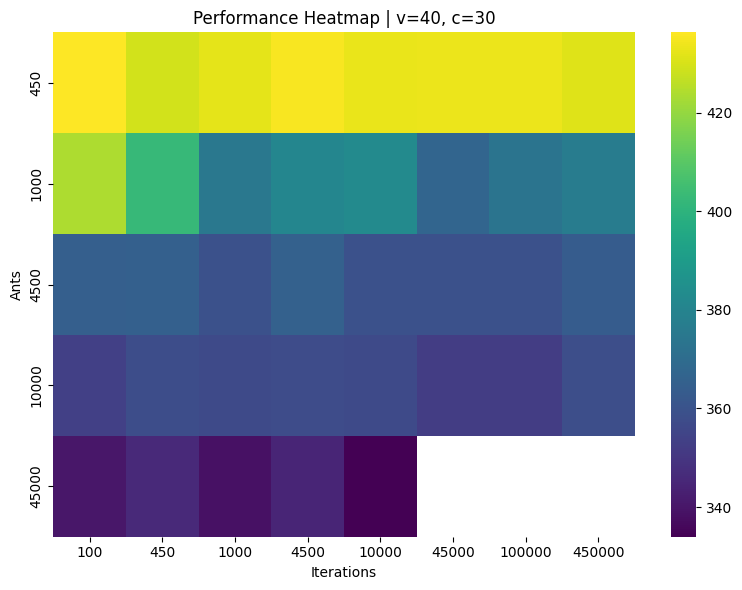

count     37.000000
mean     378.072505
std       33.474169
min      334.000000
25%      357.000000
50%      364.600000
75%      402.511494
max      436.255556
Name: cost, dtype: float64


In [24]:
last_selection = [(40,10), (40,30), (15,20), (10,10)] # v,c

mask = False

for v, c in last_selection:
    mask |= ((df_valid['v'] == v) & (df_valid['c'] == c))

df_last = df_valid[mask].copy()

v0, c0 = last_selection[1]

subset = df_last[
    (df_last['v'] == v0) &
    (df_last['c'] == c0)
]
import numpy as np

subset = subset[np.isfinite(subset['cost'])]

surface = (
    subset
    .groupby(['ants','it'])['cost']
    .mean()
    .reset_index()
)

import seaborn as sns
import matplotlib.pyplot as plt

pivot = surface.pivot(index='ants', columns='it', values='cost')

plt.figure(figsize=(8,6))
sns.heatmap(pivot, cmap="viridis")
plt.title(f"Performance Heatmap | v={v0}, c={c0}")
plt.xlabel("Iterations")
plt.ylabel("Ants")
plt.tight_layout()
plt.show()
print(surface['cost'].describe())



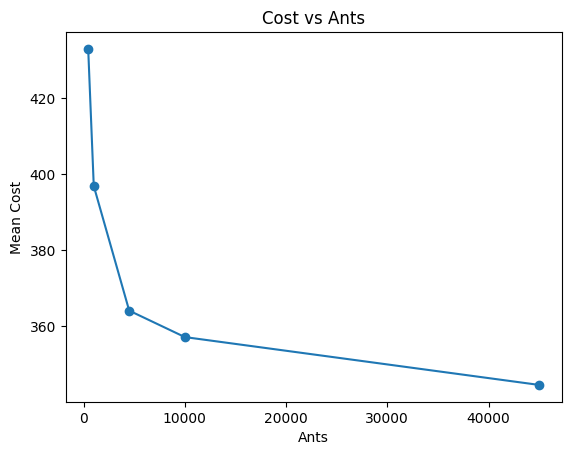

In [25]:
ants_curve = (
    subset
    .groupby('ants')['cost']
    .mean()
    .reset_index()
)

plt.figure()
plt.plot(ants_curve['ants'], ants_curve['cost'], marker='o')
plt.xlabel("Ants")
plt.ylabel("Mean Cost")
plt.title("Cost vs Ants")
plt.show()


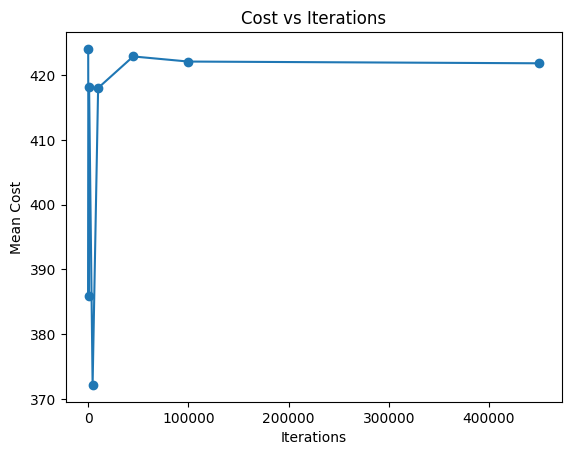

In [26]:
it_curve = (
    subset
    .groupby('it')['cost']
    .mean()
    .reset_index()
)

plt.figure()
plt.plot(it_curve['it'], it_curve['cost'], marker='o')
plt.xlabel("Iterations")
plt.ylabel("Mean Cost")
plt.title("Cost vs Iterations")
plt.show()


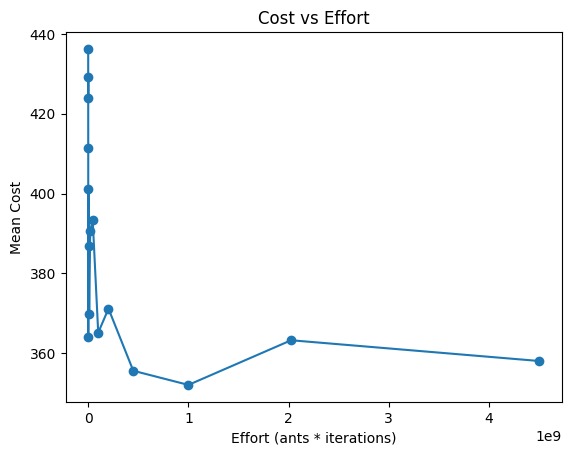

In [27]:
subset['effort'] = subset['ants'] * subset['it']

effort_curve = (
    subset
    .groupby('effort')['cost']
    .mean()
    .reset_index()
)

plt.figure()
plt.plot(effort_curve['effort'], effort_curve['cost'], marker='o')
plt.xlabel("Effort (ants * iterations)")
plt.ylabel("Mean Cost")
plt.title("Cost vs Effort")
plt.show()


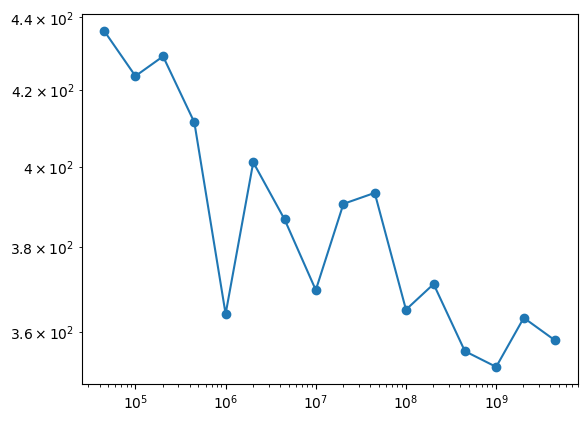

In [28]:
plt.figure()
plt.loglog(effort_curve['effort'], effort_curve['cost'], marker='o')
plt.show()


In [29]:
threshold = 0.25
effort_curve_filtered = effort_curve[effort_curve['effort'] > threshold]

import numpy as np
from sklearn.linear_model import LinearRegression

x = np.log(effort_curve_filtered['effort']).values.reshape(-1,1)
y = np.log(effort_curve_filtered['cost']).values

model = LinearRegression()
model.fit(x,y)

alpha = -model.coef_[0]
print("Exponent α ≈", alpha)


Exponent α ≈ 0.016723108198783584


In [30]:
import numpy as np
from sklearn.linear_model import LinearRegression

x = np.log(effort_curve_filtered['effort']).values.reshape(-1,1)
y = np.log(effort_curve_filtered['cost']).values

model = LinearRegression()
model.fit(x,y)

alpha = -model.coef_[0]
A = np.exp(model.intercept_)
r2 = model.score(x,y)

print("alpha =", alpha)
print("A =", A)
print("R^2 =", r2)


alpha = 0.016723108198783584
A = 506.8287407590186
R^2 = 0.7414649870967267


In [31]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Variables
X = np.log(subset[['ants','it']].values)
y = subset['cost'].values


# Polinomio grado 2
poly = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)

r2 = model.score(X_poly, y)

print("R^2 polinomio 2D grado 2:", r2)
print("Coeficientes:", model.coef_)
print("Intercepto:", model.intercept_)


R^2 polinomio 2D grado 2: 0.6884080757790043
Coeficientes: [-2.98410469e+02  7.61615591e+01  4.08493195e+01 -2.71394282e+01
  2.13280491e+00 -1.83832923e+00  1.42409589e+00  2.79570299e-01
 -1.29680861e-01]
Intercepto: 1259.5532622473654


In [32]:
import numpy as np
from sklearn.linear_model import LinearRegression

x = np.log(effort_curve_filtered['effort']).values.reshape(-1,1)
y = np.log(effort_curve_filtered['cost']).values

model = LinearRegression()
model.fit(x,y)

alpha = -model.coef_[0]
A = np.exp(model.intercept_)
r2 = model.score(x,y)

print("alpha =", alpha)
print("A =", A)
print("R^2 =", r2)


alpha = 0.016723108198783584
A = 506.8287407590186
R^2 = 0.7414649870967267


In [33]:
ants_curve = (
    subset
    .groupby('ants')['cost']
    .mean()
    .reset_index()
)
import numpy as np
from sklearn.linear_model import LinearRegression

X = ants_curve['ants'].values.reshape(-1,1)
y = np.log(ants_curve['cost'].values)

model_exp = LinearRegression()
model_exp.fit(X, y)

k = -model_exp.coef_[0]
A = np.exp(model_exp.intercept_)
r2_exp = model_exp.score(X, y)

print("Modelo exponencial:")
print("k =", k)
print("A =", A)
print("R^2 =", r2_exp)

from sklearn.preprocessing import PolynomialFeatures

X = ants_curve[['ants']].values
y = ants_curve['cost'].values

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

model_poly = LinearRegression()
model_poly.fit(X_poly, y)

r2_poly = model_poly.score(X_poly, y)

print("\nModelo polinomial grado 2:")
print("R^2 =", r2_poly)
print("Coeficientes =", model_poly.coef_)
print("Intercepto =", model_poly.intercept_)



Modelo exponencial:
k = 3.3949360826318515e-06
A = 393.80009830261383
R^2 = 0.4759536497718728

Modelo polinomial grado 2:
R^2 = 0.8163654492612706
Coeficientes = [-8.42497373e-03  1.51751322e-07]
Intercepto = 416.6966912947714


In [34]:
beta1 = model_poly.coef_[0]
beta2 = model_poly.coef_[1]

a_opt = -beta1 / (2 * beta2)

print("Ants óptimo estimado:", a_opt)


Ants óptimo estimado: 27759.14438061248


In [35]:
ants_curve = (
    subset
    .groupby('it')['cost']
    .mean()
    .reset_index()
)
import numpy as np
from sklearn.linear_model import LinearRegression

X = ants_curve['it'].values.reshape(-1,1)
y = np.log(ants_curve['cost'].values)

model_exp = LinearRegression()
model_exp.fit(X, y)

k = -model_exp.coef_[0]
A = np.exp(model_exp.intercept_)
r2_exp = model_exp.score(X, y)

print("Modelo exponencial:")
print("k =", k)
print("A =", A)
print("R^2 =", r2_exp)

from sklearn.preprocessing import PolynomialFeatures

X = ants_curve[['it']].values
y = ants_curve['cost'].values

poly = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly.fit_transform(X)

model_poly = LinearRegression()
model_poly.fit(X_poly, y)

r2_poly = model_poly.score(X_poly, y)

print("\nModelo polinomial grado 2:")
print("R^2 =", r2_poly)
print("Coeficientes =", model_poly.coef_)
print("Intercepto =", model_poly.intercept_)


Modelo exponencial:
k = -9.873846768972526e-08
A = 407.1328464141632
R^2 = 0.09303599824106301

Modelo polinomial grado 2:
R^2 = 0.22486459906505707
Coeficientes = [ 6.45126553e-04 -5.26327576e-09  8.72848387e-15]
Intercepto = 401.9854877599648


In [36]:
from sklearn.linear_model import LogisticRegression

X = df[['v','c','ants','it']]
y = df['feasible']

model = LogisticRegression(max_iter=1000)
model.fit(X, y)

print("Accuracy:", model.score(X,y))


Accuracy: 0.9276833872707659


In [37]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42
)

rf.fit(X,y)

df['prob_feasible'] = rf.predict_proba(X)[:,1]

print("Accuracy:", rf.score(X,y))


Accuracy: 0.9484492988133765


In [38]:
import numpy as np
import pandas as pd

v_vals = df['v'].unique()
c_vals = df['c'].unique()

ants_vals = np.linspace(df['ants'].min(),
                        df['ants'].max(), 30)

it_vals = np.linspace(df['it'].min(),
                      df['it'].max(), 30)

grid = pd.DataFrame(
    [(v,c,a,i) for v in v_vals
                 for c in c_vals
                 for a in ants_vals
                 for i in it_vals],
    columns=['v','c','ants','it']
)

grid['prob'] = rf.predict_proba(grid[['v','c','ants','it']])[:,1]
grid[(grid['v'] == 10) & (grid['c'] == 30)]['prob'].max()
# best = grid.loc[grid['prob'].idxmax()]
# best.head()


np.float64(0.37906824892586255)

In [46]:
v = 40
c = 30

df_vc = df[(df['v']==v) & (df['c']==c)]
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression

X = df_vc[['ants','it']]
y = df_vc['feasible']

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

model = LogisticRegression(max_iter=2000)
model.fit(X_poly, y)

coef = model.coef_[0]
intercept = model.intercept_[0]

print(coef)
print(intercept)
print("Accuracy:", model.score(X_poly,y))


[-1.71928964e-08 -1.93987336e-05  7.93734605e-06  1.42188014e-08
  3.32085044e-11]
-9.107784491551912e-10
Accuracy: 0.8387635756056808


In [47]:
import numpy as np
import pandas as pd

ants_min, ants_max = df_vc['ants'].min(), df_vc['ants'].max()
it_min, it_max = df_vc['it'].min(), df_vc['it'].max()

ants_grid = np.linspace(ants_min, ants_max, 200)
it_grid = np.linspace(it_min, it_max, 200)

grid = pd.DataFrame(
    [(a,i) for a in ants_grid for i in it_grid],
    columns=['ants','it']
)

X_grid = poly.transform(grid[['ants','it']])
grid['prob'] = model.predict_proba(X_grid)[:,1]
best = grid.loc[grid['prob'].idxmax()]

print("Ants óptimo:", best['ants'])
print("It óptimo:", best['it'])
print("Probabilidad máxima estimada:", best['prob'])


Ants óptimo: 2044.7236180904522
It óptimo: 212615.57788944722
Probabilidad máxima estimada: 1.0


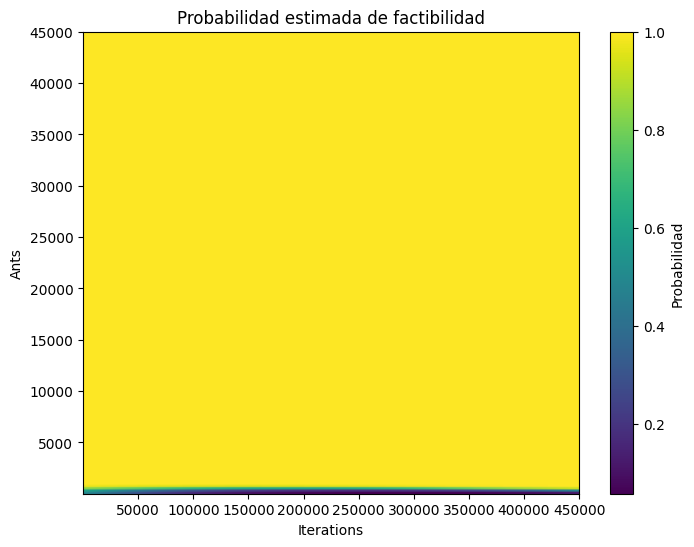

In [48]:
import matplotlib.pyplot as plt

pivot = grid.pivot(index='ants', columns='it', values='prob')

plt.figure(figsize=(8,6))
plt.imshow(pivot, origin='lower',
           extent=[it_min,it_max,ants_min,ants_max],
           aspect='auto')
plt.colorbar(label="Probabilidad")
plt.xlabel("Iterations")
plt.ylabel("Ants")
plt.title("Probabilidad estimada de factibilidad")
plt.show()


In [63]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression

X = df[['v','c','ants','it']]
y = df['feasible']

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

model = LogisticRegression(max_iter=3000, C=0.1)
model.fit(X_poly, y)

ants_vals = np.linspace(df['ants'].min(), df['ants'].max(), 200)
it_vals = np.linspace(df['it'].min(), df['it'].max(), 200)

grid = pd.DataFrame(
    [(10,10,a,i) for a in ants_vals for i in it_vals],
    columns=['v','c','ants','it']
)

Xg = poly.transform(grid)
grid['prob'] = model.predict_proba(Xg)[:,1]


threshold = 0.99
candidates = grid[grid['prob'] >= threshold]
best = candidates.sort_values(['ants','it']).iloc[0]
print(best)


v           10.000000
c           10.000000
ants       462.160804
it      341481.407035
prob         0.990162
Name: 551, dtype: float64


In [77]:
#veamos para un caso puntual
v = 28
c = 55

ants_vals = np.linspace(df['ants'].min(), df['ants'].max(), 200)
it_vals = np.linspace(df['it'].min(), df['it'].max(), 200)

grid = pd.DataFrame(
    [(v,c,a,i) for a in ants_vals for i in it_vals],
    columns=['v','c','ants','it']
)

Xg = poly.transform(grid)
grid['prob'] = model.predict_proba(Xg)[:,1]


threshold = 0.99
candidates = grid[grid['prob'] >= threshold]
best = candidates.sort_values(['ants','it']).iloc[0]
print(best)

v           28.000000
c           55.000000
ants      9279.296482
it      443217.587940
prob         0.991718
Name: 8396, dtype: float64


Configuración más cercana en datos reales:
ants        4.500000e+02
it          4.500000e+05
emp_rate    1.000000e+00
dist        1.177629e+10
Name: 23, dtype: float64


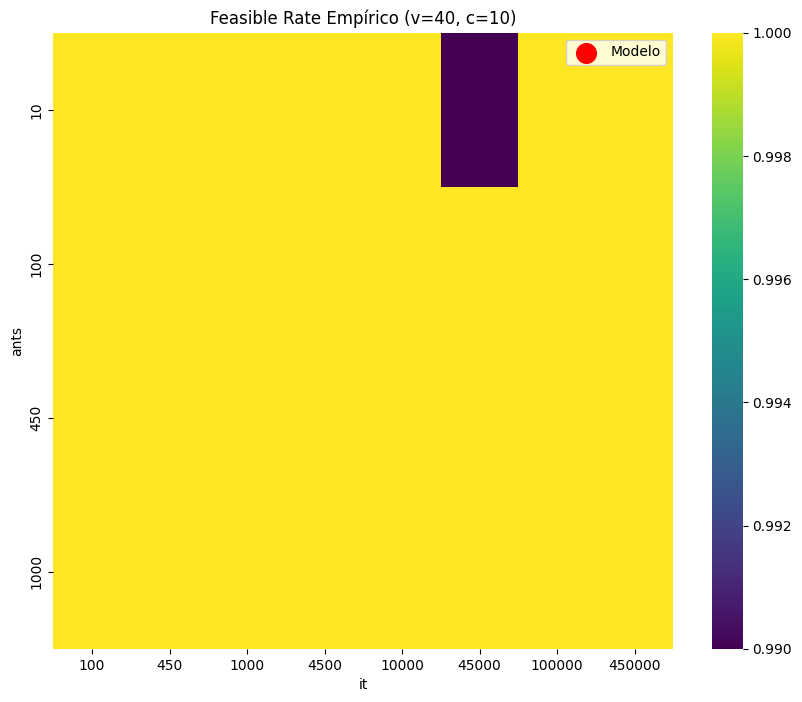

In [64]:
subset = df[(df['v'] == 40) & (df['c'] == 10)].copy()
empirical = (
    subset
    .groupby(['ants','it'])['feasible']
    .mean()
    .reset_index()
)

empirical.rename(columns={'feasible':'emp_rate'}, inplace=True)
best_ants = best['ants']
best_it = best['it']

empirical['dist'] = (
    (empirical['ants'] - best_ants)**2 +
    (empirical['it'] - best_it)**2
)

best_real = empirical.loc[empirical['dist'].idxmin()]

print("Configuración más cercana en datos reales:")
print(best_real)

import matplotlib.pyplot as plt
import seaborn as sns

pivot = empirical.pivot(index='ants', columns='it', values='emp_rate')

plt.figure(figsize=(10,8))
sns.heatmap(pivot, cmap='viridis')

plt.scatter(
    best_real['it'], 
    best_real['ants'], 
    color='red', 
    s=200, 
    label='Modelo'
)

plt.title('Feasible Rate Empírico (v=40, c=10)')
plt.legend()
plt.show()
